<a href="https://colab.research.google.com/github/feliperalde-sys/gdbs2/blob/main/Entrega_2_Completa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Entrega 2 — Bebidas del Maipo S.A. (Grupo 2)
## Planificación táctica de 13 semanas: formulación, resolución y puente

Este cuaderno reúne, en orden, las tres partes de la Entrega 2:

| Parte | Contenido |
| :--- | :--- |
| **A** | Formulación del modelo de lot-sizing capacitado (MIP) con los elementos mínimos del enunciado. |
| **B** | Resolución con PuLP y CBC, política de referencia, sensibilidad, cuadro de mando y pregunta de decisión. |
| **C** | Programa congelado de la semana 12 y horas de preparación supuestas (puente a la Entrega Final). |

**Cómo ejecutarlo.** Desde la raíz del repositorio: `pip install -r requirements.txt`, abrir este cuaderno
(Jupyter, VS Code o Colab) y ejecutar todas las celdas. Alternativa sin Jupyter: `python run_entrega2.py`.
La resolución completa tarda cerca de 20 minutos.

Los datos de entrada (`datos/` y la tabla de traspaso de la Entrega 1) se leen sin modificar. El entorno se
prepara una sola vez, en la primera celda de código; las Partes B y C reutilizan sus variables.

In [ ]:
# Paso 0: deja listo el entorno. Si el cuaderno se ejecuta fuera del repositorio (p. ej. en Colab), descarga desde GitHub
# el código del modelo (paquete `entrega2`) y los datos sin modificar. Dentro del repositorio no hace nada.
import os, subprocess, sys, urllib.request
from pathlib import Path
from urllib.parse import quote

def _repositorio_a_la_vista():
    c = Path.cwd()
    return any((d / 'entrega2').is_dir() or (d / 'Entrega 2' / 'entrega2').is_dir() for d in [c, *c.parents])

if _repositorio_a_la_vista():
    print('Repositorio detectado: se usan el código y los datos locales.')
else:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'PuLP==2.9.0'], check=True)
    # Commit del repositorio con que se obtuvieron los resultados (fija las versiones del código y de los datos).
    BASE = 'https://raw.githubusercontent.com/feliperalde-sys/gdbs2/8510b2c388c45e9fac8884af06ba24bcd89b562a/'
    RAIZ = Path('entrega2_trabajo').resolve()
    ARCHIVOS = ['Entrega 2/entrega2/' + n for n in ['__init__.py', 'analisis.py', 'heuristicas.py', 'modelo.py', 'parametros.py']]
    ARCHIVOS += ['datos/' + n for n in ['maestro_sku.csv', 'capacidad_horizonte.csv', 'inventario_inicial.csv',
                 'setups_cip.csv', 'compromisos_semana_focal.csv', 'demanda_semanal.csv']]
    ARCHIVOS.append('Entrega 2/Parte A Formulación/tabla_traspaso_entrega2.csv')
    BASE_MAIN = 'https://raw.githubusercontent.com/feliperalde-sys/gdbs2/main/'   # respaldo para los datos
    for ruta in ARCHIVOS:
        destino = RAIZ / ruta
        if destino.exists():            # al volver a ejecutar la celda no se descarga de nuevo
            continue
        destino.parent.mkdir(parents=True, exist_ok=True)
        try:
            urllib.request.urlretrieve(BASE + quote(ruta, safe='/'), destino)
        except Exception:
            urllib.request.urlretrieve(BASE_MAIN + quote(ruta, safe='/'), destino)
    os.chdir(RAIZ / 'Entrega 2')
    print('Entorno creado en', Path.cwd(), '| archivos descargados de GitHub:', len(ARCHIVOS))

# Entrega 2 — Parte A: Formulación del modelo de *lot-sizing* capacitado

**Caso integrador Bebidas del Maipo S.A.** · Gestión de Producción de Bienes y Servicios · USACH · Grupo 2

Este notebook deduce, paso a paso, el modelo de planificación de producción e inventario para las
13 semanas del horizonte táctico (28/09/2026 a 21/12/2026). Cada uno de los ocho elementos mínimos
del enunciado (sección 7.1) tiene su propia sección: primero se explica la idea, luego se deduce la
restricción y al final se muestra con los datos.

| Punto | Elemento del enunciado | Bloque en `entrega2/modelo.py` |
| :--- | :--- | :--- |
| 1 | Balance de inventario con *backlogging* y rendimiento | `r1_balance` |
| 2 | Variables binarias de preparación y cota $M_{it}$ justificada | `r2_preparacion` |
| 3 | Capacidad de envasado por línea y de mezcla en litros | `r3_capacidad` |
| 4 | Stock de seguridad $SS_{it}$ | `r4_stock_seguridad` |
| 5 | Horas extra acotadas | `r5_horas_extra` |
| 6 | Lote mínimo y *lead time* de jarabe | `r6_lote_minimo` (+ bloque 3) |
| 7 | Restricción de fin de horizonte | `r7_terminal` |
| 8 | Pedidos en firme de la semana 12 | `r8_pedidos_firme` |

**Entradas.** Los datos crudos de `datos/` y la tabla de traspaso de la Entrega 1
(`tabla_traspaso_entrega2.csv`), que se usa **tal como fue entregada**. Ningún archivo de entrada se
modifica: toda transformación ocurre en código.

**Cómo ejecutar.** Desde la raíz del repositorio: `python run_entrega2.py`. También puede abrirse en
Jupyter o Colab y ejecutarse de arriba hacia abajo.

In [ ]:
# Preparación del entorno: ubica el paquete `entrega2` (carpeta "Entrega 2") y lo importa.
import sys
from pathlib import Path

carpeta = Path.cwd()
while not (carpeta / "entrega2").is_dir() and carpeta != carpeta.parent:
    if (carpeta / "Entrega 2" / "entrega2").is_dir():   # el cuaderno se abrió desde la raíz del repositorio
        carpeta = carpeta / "Entrega 2"
        break
    carpeta = carpeta.parent
sys.path.insert(0, str(carpeta))

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pulp as pl

from entrega2 import parametros as pa, modelo as mo, analisis as an, heuristicas as he

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pa.RESULTADOS.mkdir(parents=True, exist_ok=True)
pa.FIGURAS.mkdir(parents=True, exist_ok=True)
print("Paquete cargado desde:", carpeta)
print("PuLP", pl.__version__, "| solvers disponibles:", pl.listSolvers(onlyAvailable=True))

Paquete cargado desde: /home/claude/gdbs2/Entrega 2
PuLP 2.9.0 | solvers disponibles: ['PULP_CBC_CMD']


## 0. Revisión de los datos de entrada

El enunciado advierte que los datos provienen de un ERP real y **no están limpios**. Antes de
formular se revisan los archivos que usa esta entrega. Cada hallazgo queda con la decisión tomada.

In [ ]:
tablas = pa.cargar_datos()
for nombre, df in tablas.items():
    print(f"{nombre:<14} {df.shape[0]:>5} filas x {df.shape[1]:>2} columnas")

hallazgos = pa.validar_datos(tablas)
display(hallazgos)

maestro            9 filas x 13 columnas
capacidad         13 filas x 14 columnas
inventario         9 filas x  5 columnas
setups             9 filas x  5 columnas
compromisos       15 filas x 10 columnas
demanda_hist    1404 filas x 10 columnas
traspaso         117 filas x 14 columnas


,Archivo,Chequeo,Resultado,Decisión
0,tabla_traspaso,"117 filas, 9 SKU x 13 semanas, sin duplicados","117 filas, duplicados=0",Se usa sin modificar.
1,tabla_traspaso,Valores faltantes en parámetros clave,0,Ninguno.
2,tabla_traspaso,Semanas con pronóstico 0,FUN-B30: 9,FUN-B30 es intermitente (69 de 156 semanas con venta 0); se respeta el pronóstico de la Entrega 1 y el SS cubre la incertidumbre.
3,tabla_traspaso,σ̂ desproporcionado respecto del pronóstico,"CIT-L05 h=4: σ̂=10,663 vs d̂=1,740; CIT-L05 h=9: σ̂=10,588 vs d̂=2,326","Origen: venta de 32.916 cajas de CIT-L05 el 29/12/2025 (vecinas ~2.600, sin promoción ni quiebre). No se corrige la Entrega 1; se evalúa en sensibilidad."
4,capacidad_horizonte,Horas regulares ya netas de mantención,L2 sem. 4 y 9: 40 h = 48 - 8; mezcla sem. 6: 49 h = 55 - 6,"Se usan las horas regulares tal cual, sin volver a descontar mantenciones."
5,capacidad_horizonte,Semana 13 con menos horas sin mantención declarada,"mezcla 47 h, L1 36 h, L2 40 h",Semana de Navidad (25/12). Se respeta el dato.
6,capacidad_horizonte,Tarifa de hora extra de L1,No existe columna para L1,Supuesto: misma tarifa que L2 (168.000 CLP/h).
7,inventario_inicial,"Inventario inicial, lote mínimo y nivel de servicio","9 SKU, sin negativos=True",Se usan tal cual. No hay inventario de jarabe ni atrasos iniciales.
8,compromisos_semana_focal,Cartera en firme mayor que el pronóstico de la semana 12,FUN-B30: 66 > 0,"La demanda de la semana 12 se toma como máx(pronóstico, cartera)."
9,compromisos_semana_focal,Línea y familia coherentes con el maestro,discrepancias=0,Ninguna.


**Lectura de la revisión.**

- La tabla de traspaso está completa (117 filas, sin faltantes). Se usa sin cambios, porque es el
  compromiso de la Entrega 1.
- La anomalía más importante es la **desviación del error de CIT-L05 en los horizontes 4 y 9**: es
  unas 6 veces el pronóstico. Viene de una venta registrada de 32.916 cajas el 29/12/2025. Las semanas
  vecinas rondan las 2.600 cajas, no hubo promoción ni quiebre de stock, y los otros SKU de la familia
  vendieron normal esa semana. Todo apunta a un error de digitación. No corregimos la Entrega 1:
  el escenario base usa la tabla tal cual y el impacto del dato se mide como sensibilidad en la Parte B.
- Las horas regulares de `capacidad_horizonte.csv` **ya vienen netas de mantención** (L2 trabaja 40 h
  en las semanas 4 y 9 = 48 − 8). Descontarlas de nuevo sería contar dos veces la misma pérdida.
- No existe tarifa de hora extra para L1. Se supone la misma de L2 y se declara.

In [ ]:
# Contexto del dato atípico de CIT-L05 (solo lectura del histórico).
hist = tablas["demanda_hist"]
ventana = hist[(hist.fecha_lunes >= "2025-12-08") & (hist.fecha_lunes <= "2026-01-19")]
display(ventana.pivot(index="fecha_lunes", columns="sku", values="ventas_cajas")[["CIT-L05", "CIT-L15", "CIT-L30"]])

sku,CIT-L05,CIT-L15,CIT-L30
fecha_lunes,,,
2025-12-08,"2,609.00","2,924.00",673.00
2025-12-15,"2,435.00","2,820.00",544.00
2025-12-22,"2,555.00","3,615.00",471.00
2025-12-29,"32,916.00","2,320.00",628.00
2026-01-05,"2,584.00","3,013.00",512.00
2026-01-12,"2,866.00","2,667.00",562.00
2026-01-19,"2,661.00","2,267.00",715.00


## Conjuntos, índices y parámetros

| Símbolo | Definición | Fuente |
| :--- | :--- | :--- |
| $i \in \mathcal{I}$ | SKU (9 productos) | `maestro_sku.csv` |
| $t \in \{1,\dots,13\}$ | Semana del horizonte | `capacidad_horizonte.csv` |
| $\ell \in \{L1, L2\}$ | Línea de envasado; $\ell(i)$ es la línea del SKU $i$ | maestro |
| $f \in \{CIT, FUN, NEC\}$ | Familia; $f(i)$ es la familia del SKU $i$ | maestro |
| $\hat d_{it}$ | Pronóstico de demanda (cajas) | traspaso E1 |
| $\hat\sigma_{i,h}$ | Desviación estándar del error de pronóstico a horizonte $h=t$ | traspaso E1 |
| $m_{\ell}$ | Tasa de merma efectiva de la línea | traspaso E1 |
| $L^{ef}_i$ | Litros de jarabe por caja, con sobrellenado | traspaso E1 |
| $v_i$ | Tasa de envasado (cajas/h) | maestro |
| $H_{\ell t}, \bar E_{\ell t}$ | Horas regulares y máximo de horas extra de la línea | capacidad |
| $H^m_t, \bar E^m_t, r^m_t$ | Horas regulares, extra máximas y tasa (L/h) de la mezcladora | capacidad |
| $c_i, h_i, \pi_i$ | Costo variable, costo de inventario y penalidad de atraso | maestro |
| $I_{i0}, LM_i, \alpha_i$ | Inventario inicial, lote mínimo y nivel de servicio | inventario inicial |
| $C_i$ | Cartera en firme de la semana 12 | compromisos |

**Variables de decisión**

| Variable | Tipo | Significado |
| :--- | :--- | :--- |
| $x_{it}$ | continua $\ge 0$ | Cajas producidas (brutas, antes de merma) |
| $I_{it}$, $B_{it}$ | continuas $\ge 0$ | Inventario y atraso al cierre de la semana |
| $u_{it}$ | continua $\ge 0$ | Déficit respecto del stock de seguridad |
| $y_{it}$ | binaria | 1 si el SKU se prepara (produce) en la semana |
| $w_{\ell f t}$ | binaria | 1 si la línea $\ell$ abre una campaña de la familia $f$ en la semana |
| $n_{ft}$ | continua $\ge 0$ | Cambios de formato dentro de la familia $f$ en L2 |
| $E_{\ell t}$, $E^m_s$ | continuas $\ge 0$ | Horas extra de envasado y de mezcla |
| $V_{fs}$ | continua $\ge 0$ | Litros de jarabe de la familia $f$ mezclados en la semana $s$ |
| $z_{fs}$ | binaria | 1 si la mezcladora prepara jarabe de la familia $f$ en la semana $s$ |

In [ ]:
P = pa.construir_parametros(pa.Escenario())
print("SKU:", P["SKUS"])
print("Familias:", P["FAMILIAS"], "| Líneas:", P["LINEAS"], "| Semanas:", P["T"][0], "a", P["T"][-1])
display(tablas["maestro"].set_index("sku")[["familia", "formato_L", "linea_envasado", "tasa_envasado_cajas_h",
                                            "costo_variable_caja_clp", "costo_inventario_caja_semana_clp",
                                            "penalidad_atraso_caja_semana_clp"]])

SKU: ['NEC-D05', 'NEC-D15', 'NEC-D30', 'CIT-L05', 'CIT-L15', 'CIT-L30', 'FUN-B05', 'FUN-B15', 'FUN-B30']
Familias: ['CIT', 'FUN', 'NEC'] | Líneas: ['L1', 'L2'] | Semanas: 1 a 13


,familia,formato_L,linea_envasado,tasa_envasado_cajas_h,costo_variable_caja_clp,costo_inventario_caja_semana_clp,penalidad_atraso_caja_semana_clp
sku,,,,,,,
NEC-D05,NEC,0.50,L1,180,3840,95,1400
NEC-D15,NEC,1.50,L2,210,5760,95,1400
NEC-D30,NEC,3.00,L2,130,7680,95,1400
CIT-L05,CIT,0.50,L1,180,2820,95,1400
CIT-L15,CIT,1.50,L2,210,4230,95,1400
CIT-L30,CIT,3.00,L2,130,5640,95,1400
FUN-B05,FUN,0.50,L1,180,4860,95,1400
FUN-B15,FUN,1.50,L2,210,7290,95,1400
FUN-B30,FUN,3.00,L2,130,9720,95,1400


# Punto 1 (1/8)
### 1. Balance de inventario por SKU y semana

Cada semana, lo disponible debe explicar lo atendido y lo que se difiere. Para el SKU $i$ en la
semana $t$, el **inventario neto** ($I_{it}-B_{it}$) cambia por la producción útil y la demanda:

$$
I_{it}-B_{it} \;=\; I_{i,t-1}-B_{i,t-1} \;+\; \rho_{\ell(i)}\,x_{it} \;-\; d_{it}
\qquad \forall i,t
$$

con $I_{it}\ge 0$ y $B_{it}\ge 0$. Para $t=1$ se usan el inventario inicial $I_{i0}$ del archivo y
$B_{i0}=0$, porque no hay atrasos declarados al inicio.

#### 1.1. Rendimiento heredado de la Entrega 1

La carta $p$ de la Entrega 1 entregó una tasa de merma $m_\ell$ por línea. El rendimiento es
$\rho_\ell = 1-m_\ell$, y $x_{it}$ representa la producción **bruta**. Por eso, para obtener $q$ cajas
vendibles hay que producir $q/(1-m_\ell)$, como pide el enunciado.

Por ejemplo, con $m_{L2}=3{,}11\,\%$, producir 1.000 cajas brutas deja 968,9 cajas vendibles.

La merma se aplica **una sola vez**, en la producción. No se descuenta de nuevo del inventario ni se
suma a la demanda.

#### 1.2. Pedidos atrasados (*backlogging*)

La demanda no atendida queda pendiente en $B_{it}$ y se arrastra a la semana siguiente. Cada caja
atrasada cuesta $\pi_i = 1.400$ CLP por **cada** semana que permanece pendiente:

$$
C_{\text{atraso}} = \sum_i\sum_t \pi_i\,B_{it}
$$

#### 1.3. Demanda de la semana 12

En la semana 12 hay cartera en firme. Si la cartera supera al pronóstico, el pronóstico subestima lo
que ya está vendido. Por eso se usa $d_{i,12}=\max(\hat d_{i,12},\,C_i)$, y en las demás semanas
$d_{it}=\hat d_{it}$.

In [ ]:
rend = pd.DataFrame({"Línea": P["linea"], "Merma m (%)": {i: 100 * P["merma"][i] for i in P["SKUS"]},
                     "Rendimiento ρ (%)": {i: 100 * P["rend"][i] for i in P["SKUS"]},
                     "Cajas brutas por 1.000 vendibles": {i: 1000 / P["rend"][i] for i in P["SKUS"]}})
display(rend)

m_demo, v_demo = mo.construir_modelo(P, bloques=[mo.r1_balance])
print("Restricciones de balance:", len(m_demo.constraints), "(9 SKU x 13 semanas)")
print("Ejemplo, CIT-L15 semana 1:\n ", m_demo.constraints["balance_CIT_L15_1"])

,Línea,Merma m (%),Rendimiento ρ (%),Cajas brutas por 1.000 vendibles
NEC-D05,L1,1.92,98.08,"1,019.59"
NEC-D15,L2,3.11,96.89,"1,032.15"
NEC-D30,L2,3.11,96.89,"1,032.15"
CIT-L05,L1,1.92,98.08,"1,019.59"
CIT-L15,L2,3.11,96.89,"1,032.15"
CIT-L30,L2,3.11,96.89,"1,032.15"
FUN-B05,L1,1.92,98.08,"1,019.59"
FUN-B15,L2,3.11,96.89,"1,032.15"
FUN-B30,L2,3.11,96.89,"1,032.15"


Restricciones de balance: 117 (9 SKU x 13 semanas)
Ejemplo, CIT-L15 semana 1:
  -B_('CIT_L15',_1) + I_('CIT_L15',_1) - 0.9688542488020865*x_('CIT_L15',_1) = -563.27269338891


# Punto 2 (2/8)
### 2. Variables binarias de preparación y su enlace con la producción

Producir un SKU obliga a preparar la línea: limpiar, cambiar formato y ajustar el envasado. Eso
consume tiempo y dinero aunque se produzca una sola caja. Se modela con $y_{it}\in\{0,1\}$:

$$
x_{it} \le M_{it}\,y_{it} \qquad \forall i,t
$$

Si $y_{it}=0$, la producción es cero. Si $y_{it}=1$, puede producirse hasta $M_{it}$.

#### 2.1. Cota $M_{it}$ justificada

Un $M$ demasiado grande hace que la relajación lineal "pague" una fracción mínima de la preparación
($y_{it}=x_{it}/M$), y el solver tarda más en cerrar la brecha. Por eso se usa el **menor** de tres
límites, todos válidos porque ninguna solución óptima puede superarlos:

$$
M_{it}=\min\Big\{\underbrace{v_i\,(H_{\ell(i)t}+\bar E_{\ell(i)t})}_{\text{(a) línea completa}},\;
\underbrace{\tfrac{r^m_{t-1}\,(H^m_{t-1}+\bar E^m_{t-1}-\text{CIP})}{L^{ef}_i}}_{\text{(b) mezcla de } t-1},\;
\underbrace{\tfrac{\sum_{k\ge t} d_{ik}+\max_k SS_{ik}+T_i}{\rho_{\ell(i)}}}_{\text{(c) necesidad restante}}\Big\}
$$

- **(a)** Ni dedicando toda la línea (regular y extra) a un solo SKU se supera $v_i(H+\bar E)$.
- **(b)** El jarabe para envasar en $t$ se mezcla en $t-1$ (punto 6), así que tampoco puede superarse
  lo que la mezcladora alcanza a preparar esa semana.
- **(c)** Producir más que toda la demanda restante, más la mayor reserva y la reserva terminal, no
  tiene sentido económico.

#### 2.2. Campañas por familia

Las limpiezas CIP dependen de la **familia** y no del SKU (sección 2.3 del enunciado). Por eso se
agrega $w_{\ell f t}$: la línea abre una campaña de la familia $f$ si produce al menos uno de sus SKU.

$$
y_{it} \le w_{\ell(i) f(i) t}, \qquad w_{\ell f t} \le \sum_{i\in(\ell,f)} y_{it}
$$

In [ ]:
filas = []
for i in P["SKUS"]:
    l = P["linea"][i]
    for t in (1, 6, 12):
        a = P["tasa"][i] * (P["H"][(l, t)] + P["Emax"][(l, t)])
        s = t - 1
        b = (P["Hm"][s] + P["Emax_m"][s] - P["cip_mezcla"][s]) * P["tasa_mezcla"][s] / P["litros_ef"][i]
        c = (sum(P["d"][(i, k)] for k in P["T"] if k >= t) + max(P["SS"][(i, k)] for k in P["T"])
             + P["T_terminal"][i]) / P["rend"][i]
        cotas = {"(a) línea": a, "(b) mezcla": b, "(c) necesidad": c}
        filas.append({"SKU": i, "Semana": t, **cotas, "M_it": P["M"][(i, t)],
                      "Cota activa": min(cotas, key=cotas.get)})
tabla_M = pd.DataFrame(filas)
display(tabla_M.round(0))
print("Cota activa (conteo sobre las 117 combinaciones):")
conteo = {}
for i in P["SKUS"]:
    for t in P["T"]:
        l, s = P["linea"][i], t - 1
        a = P["tasa"][i] * (P["H"][(l, t)] + P["Emax"][(l, t)])
        b = (P["Hm"][s] + P["Emax_m"][s] - P["cip_mezcla"][s]) * P["tasa_mezcla"][s] / P["litros_ef"][i]
        cc = (sum(P["d"][(i, k)] for k in P["T"] if k >= t) + max(P["SS"][(i, k)] for k in P["T"])
              + P["T_terminal"][i]) / P["rend"][i]
        k = min({"línea": a, "mezcla": b, "necesidad": cc}.items(), key=lambda z: z[1])[0]
        conteo[k] = conteo.get(k, 0) + 1
print(conteo)

,SKU,Semana,(a) línea,(b) mezcla,(c) necesidad,M_it,Cota activa
0,NEC-D05,1,"8,640.00","20,390.00","18,822.00","8,640.00",(a) línea
1,NEC-D05,6,"8,640.00","24,180.00","12,764.00","8,640.00",(a) línea
2,NEC-D05,12,"8,640.00","24,180.00","5,533.00","5,534.00",(c) necesidad
3,NEC-D15,1,"13,440.00","13,707.00","32,864.00","13,440.00",(a) línea
4,NEC-D15,6,"13,440.00","16,254.00","22,549.00","13,440.00",(a) línea
5,NEC-D15,12,"13,440.00","16,254.00","9,845.00","9,846.00",(c) necesidad
6,NEC-D30,1,"8,320.00","10,283.00","7,651.00","7,651.00",(c) necesidad
7,NEC-D30,6,"8,320.00","12,194.00","4,978.00","4,979.00",(c) necesidad
8,NEC-D30,12,"8,320.00","12,194.00","2,068.00","2,068.00",(c) necesidad
9,CIT-L05,1,"8,640.00","20,390.00","51,129.00","8,640.00",(a) línea


Cota activa (conteo sobre las 117 combinaciones):
{'línea': 64, 'necesidad': 53}


**Interpretación.** En L1 y en el formato de 1,5 L domina la cota de **línea**. En el formato de
3,0 L y hacia el final del horizonte, cuando queda poca demanda por cubrir, domina la de
**necesidad**. La cota de mezcla nunca es la menor: una semana de mezcladora alcanza para más de lo
que una línea puede envasar de un solo SKU. En ningún caso se usa un número arbitrario.

# Punto 3 (3/8)
### 3. Capacidad de envasado y de mezcla

#### 3.1. Tiempo de preparación en envasado

La matriz CIP es **asimétrica**. Pasar de cítrico a berries toma 1,0 h, pero volver toma 2,4 h. El
modelo táctico decide *qué* familias se envasan cada semana, pero no *en qué orden*. Por eso cada
campaña reserva el **tiempo esperado de entrada** a su familia, que es el promedio de la columna de
la matriz:

$$
\tau_f = \frac{1}{|\mathcal F|-1}\sum_{g\ne f} \text{CIP}_{g\to f}
$$

Este promedio tiene una propiedad útil. Con las tres familias activas hay dos ciclos posibles:
CIT→FUN→NEC→CIT, que suma 5,2 h, y CIT→NEC→FUN→CIT, que suma 6,2 h. Su promedio, 5,7 h, es
exactamente $\sum_f\tau_f$. El modelo supone una secuencia "promedio". Cuánto se equivoca con la
secuencia real es justamente lo que la Entrega Final debe medir.

En **L2**, que envasa 1,5 L y 3,0 L, cambiar de formato **dentro** de una familia agrega 0,6 h y
38.000 CLP. Si una campaña incluye los dos formatos, hay un cambio; en general,
$n_{ft}\ge \sum_{i\in(L2,f)}y_{it}-w_{L2,f,t}$. En **L1** cada familia tiene un solo SKU, así que el
cambio de formato de 0,4 h nunca ocurre.

La capacidad de cada línea queda:

$$
\sum_{i\in\ell}\frac{x_{it}}{v_i}\;+\;\sum_f \tau_f\,w_{\ell f t}\;+\;0{,}6\,\sum_f n_{ft}\,\mathbb 1[\ell=L2]
\;\le\; H_{\ell t}+E_{\ell t}\qquad\forall \ell,t
$$

In [ ]:
setups = tablas["setups"].pivot(index="familia_origen", columns="familia_destino", values="horas_limpieza_cip")
print("Matriz CIP (horas), fila = sale, columna = entra:")
display(setups)
print("Tiempo esperado de entrada τ_f (h):", {f: round(v, 2) for f, v in P["tau_cip"].items()})
import itertools
for orden in itertools.permutations(["CIT", "FUN", "NEC"]):
    if orden[0] != "CIT":
        continue
    ciclo = list(orden) + [orden[0]]
    h = sum(setups.loc[a, b] for a, b in zip(ciclo, ciclo[1:]))
    print(" ciclo", " → ".join(ciclo), f"= {h:.1f} h")
print(f"Suma de τ_f = {sum(P['tau_cip'].values()):.1f} h (promedio de los ciclos)")

Matriz CIP (horas), fila = sale, columna = entra:


familia_destino,CIT,FUN,NEC
familia_origen,,,
CIT,0.00,1.00,1.00
FUN,2.40,0.00,1.40
NEC,2.80,2.80,0.00


Tiempo esperado de entrada τ_f (h): {'CIT': 2.6, 'FUN': 1.9, 'NEC': 1.2}
 ciclo CIT → FUN → NEC → CIT = 5.2 h
 ciclo CIT → NEC → FUN → CIT = 6.2 h
Suma de τ_f = 5.7 h (promedio de los ciclos)


#### 3.2. Capacidad de mezcla en litros

Una sola mezcladora prepara el jarabe de todas las familias a $r^m=2.300$ L/h. Cada familia que se
mezcla en la semana exige un CIP de 1,2 h. El jarabe por caja incluye el **sobrellenado** medido en la
Entrega 1: $L^{ef}_i = L^{nominal}_i + L^{sobrellenado}_i$. Las cajas que se pierden por merma
también consumen jarabe, porque se llenaron antes de descartarse.

$$
\frac{1}{r^m_s}\sum_f V_{fs} \;+\; 1{,}2\sum_f z_{fs} \;\le\; H^m_s + E^m_s,\qquad
V_{fs} \le r^m_s\,(H^m_s+\bar E^m_s)\,z_{fs}
$$

El jarabe mezclado en $s$ se envasa en $s+1$. Ese enlace se deduce en el punto 6.

In [ ]:
lit = pd.DataFrame({"Litros nominales": tablas["maestro"].set_index("sku").litros_por_caja,
                    "Litros efectivos": P["litros_ef"]})
lit["Sobrellenado (L/caja)"] = lit["Litros efectivos"] - lit["Litros nominales"]
display(lit)

# ¿Cuántas horas de mezcla exige el pronóstico? (sin CIP, sin merma)
horas_req = {t: sum(P["litros_ef"][i] * P["d"][(i, t)] / P["rend"][i] for i in P["SKUS"]) / P["tasa_mezcla"][t]
             for t in P["T"]}
carga = pd.DataFrame({"Horas para el pronóstico (+merma)": horas_req,
                      "Horas + 3 CIP": {t: horas_req[t] + 3 * 1.2 for t in P["T"]},
                      "Horas regulares (semana anterior)": {t: P["Hm"][t - 1] for t in P["T"]},
                      "Regular + extra (semana anterior)": {t: P["Hm"][t - 1] + P["Emax_m"][t - 1] for t in P["T"]}})
carga.index.name = "Semana de envasado"
display(carga.round(1))
print("Semanas cuya demanda (con 3 CIP) supera la mezcla regular disponible:",
      [t for t in P["T"] if carga.loc[t, "Horas + 3 CIP"] > carga.loc[t, "Horas regulares (semana anterior)"]])

,Litros nominales,Litros efectivos,Sobrellenado (L/caja)
CIT-L05,6.00,6.07,0.07
CIT-L15,9.00,9.03,0.03
CIT-L30,12.00,12.03,0.03
FUN-B05,6.00,6.07,0.07
FUN-B15,9.00,9.03,0.03
FUN-B30,12.00,12.03,0.03
NEC-D05,6.00,6.07,0.07
NEC-D15,9.00,9.03,0.03
NEC-D30,12.00,12.03,0.03


,Horas para el pronóstico (+merma),Horas + 3 CIP,Horas regulares (semana anterior),Regular + extra (semana anterior)
Semana de envasado,,,,
1,38.90,42.50,55.00,55.00
2,43.90,47.50,55.00,65.00
3,44.20,47.80,55.00,65.00
4,48.30,51.90,55.00,65.00
5,44.90,48.50,55.00,65.00
6,46.70,50.30,55.00,65.00
7,48.40,52.00,49.00,59.00
8,49.70,53.30,55.00,65.00
9,50.40,54.00,55.00,65.00


Semanas cuya demanda (con 3 CIP) supera la mezcla regular disponible: [7, 11, 12]


**Lectura.** La carga de mezcla es alta en todo el horizonte y crece hacia el final. Solo para cubrir
el pronóstico y la merma, más tres CIP, se necesitan entre 42 y 59 horas por semana. En las
semanas de envasado 7, 11 y 12 eso supera las horas regulares de la semana anterior: la semana 6
tiene 6 h de mantención, y las semanas 11 y 12 son las previas al peak. A esa carga todavía hay que
sumar el stock de seguridad y la reserva terminal. Esto confirma la
pregunta de decisión de la Parte B: la mezcladora es el cuello de botella y habrá que elegir entre
horas extra, adelantar producción o atrasar.

# Punto 4 (4/8)
### 4. Stock de seguridad

#### 4.1. Deducción

La demanda real es el pronóstico más un error: $D_{it}=\hat d_{it}+\varepsilon_{it}$. Se supone que el
error del horizonte $h$ es aproximadamente normal, con media cero y desviación $\hat\sigma_{i,h}$, que
es la medida de la Entrega 1 por origen deslizante. Queremos que, con probabilidad $\alpha_i$, la
demanda de la semana no supere lo planificado más la reserva:

$$
P\big(D_{it}\le \hat d_{it}+SS_{it}\big)\ge\alpha_i
\;\Longleftrightarrow\;
P\!\left(\frac{\varepsilon_{it}}{\hat\sigma_{i,h}}\le\frac{SS_{it}}{\hat\sigma_{i,h}}\right)\ge\alpha_i
\;\Longleftrightarrow\;
\frac{SS_{it}}{\hat\sigma_{i,h}}\ge \Phi^{-1}(\alpha_i)
$$

La menor reserva que cumple, redondeada a cajas enteras, es:

$$
SS_{it}=\left\lceil \Phi^{-1}(\alpha_i)\,\hat\sigma_{i,h}\right\rceil,\qquad h=t
$$

Con $\alpha=95\,\%$, $\Phi^{-1}=1{,}645$, y con $\alpha=92\,\%$, $\Phi^{-1}=1{,}405$. Se usa el $\hat\sigma$ del
horizonte correspondiente, porque el plan se fija hoy para las 13 semanas: el error de la semana 9 es
el error a 9 semanas.

#### 4.2. Cómo entra al modelo

La reserva se mide sobre el **inventario neto**, porque una caja que ya se debe no protege a nadie.
Si una semana no alcanza la meta, el déficit $u_{it}$ se penaliza en lugar de volver infactible el
plan:

$$
I_{it}-B_{it}+u_{it}\ \ge\ SS_{it}, \qquad C_{SS}=\sum_{i,t}\pi^{SS}_i\,u_{it}
$$

El enunciado no da un costo para el déficit de reserva. Se usa $\pi^{SS}_i=\pi_i=1.400$ CLP por
caja-semana: quedar bajo la reserva expone, en el peor caso, a un quiebre que se paga al costo de
atraso. Este valor se varía en la sensibilidad de "costo de quiebre".

In [ ]:
ss = pd.DataFrame({t: {i: P["SS"][(i, t)] for i in P["SKUS"]} for t in P["T"]})
print("Nivel de servicio α:", P["nivel_servicio"])
print("Stock de seguridad SS_it (cajas):")
display(ss)
rel = ss / pd.DataFrame({t: {i: P["pronostico"][(i, t)] for i in P["SKUS"]} for t in P["T"]}).replace(0, np.nan)
print("SS / pronóstico, valores sobre 1,5:")
display(rel.stack()[rel.stack() > 1.5].rename("SS / d̂").to_frame())

Nivel de servicio α: {'NEC-D05': 0.95, 'NEC-D15': 0.95, 'NEC-D30': 0.95, 'CIT-L05': 0.95, 'CIT-L15': 0.95, 'CIT-L30': 0.95, 'FUN-B05': 0.92, 'FUN-B15': 0.92, 'FUN-B30': 0.92}
Stock de seguridad SS_it (cajas):


,1,2,3,4,5,6,7,8,9,10,11,12,13
NEC-D05,801,439,605,1182,247,842,438,624,1167,346,847,512,646
NEC-D15,1631,1702,815,897,1161,1686,1758,1053,797,1264,1710,1931,1112
NEC-D30,155,244,180,182,177,280,246,183,190,243,289,260,176
CIT-L05,713,430,1085,17540,1501,690,377,1062,17416,1519,581,384,1034
CIT-L15,1047,1486,806,626,955,1097,1431,935,732,917,679,921,1048
CIT-L30,163,125,188,171,141,177,129,182,140,132,172,89,185
FUN-B05,1056,1052,719,957,590,1011,694,708,1074,544,960,655,1024
FUN-B15,682,270,750,1007,513,659,446,711,818,656,657,498,731
FUN-B30,210,232,132,297,220,293,267,132,282,294,300,284,153


SS / pronóstico, valores sobre 1,5:


SS / d̂
CIT-L05 4    10.08
        9     7.49

**Lectura.** Solo dos reservas superan 1,5 veces su pronóstico, y las dos son de **CIT-L05**, en
los horizontes 4 y 9: piden 17.540 y 17.416 cajas, entre 7 y 10 veces la demanda de esa semana y más
de dos semanas completas de L1. Es el efecto del dato atípico de la Entrega 1. **FUN-B30** tiene
pronóstico 0 en varias semanas por ser intermitente, así que su razón no está definida y no aparece
en la lista.

El escenario base mantiene la tabla tal cual, tal como se pidió. Como el déficit es penalizado y no
obligatorio, el modelo sigue siendo factible. La Parte B mide cuánto cuesta este dato.

# Punto 5 (5/8)
### 5. Horas extra como variable de decisión acotada

Las horas extra son una palanca de capacidad con costo explícito:

$$
0\le E_{\ell t}\le \bar E_{\ell t},\qquad 0\le E^m_s\le \bar E^m_s
$$

$$
C_{\text{extra}}=\sum_{\ell,t} c^{E}_{\ell}\,E_{\ell t}+\sum_s c^{E,m}\,E^m_s
$$

| Recurso | Máximo semanal | Costo (CLP/h) | Fuente |
| :--- | ---: | ---: | :--- |
| L1 | 8 h | 168.000 | **Supuesto**: los datos no traen tarifa para L1; se usa la de L2 |
| L2 | 16 h | 168.000 | enunciado y `capacidad_horizonte.csv` |
| Mezcla | 10 h | 121.000 | enunciado y `capacidad_horizonte.csv` |

In [ ]:
cap = tablas["capacidad"].set_index("t")
display(cap[["horas_mezcla_regular", "horas_mezcla_extra_max", "horas_L1_regular", "horas_L1_extra_max",
             "horas_L2_regular", "horas_L2_extra_max", "mantencion_programada_h_L2",
             "mantencion_programada_h_mezcla"]])
print("Costos de hora extra usados:", P["c_extra"], "| mezcla:", P["c_extra_m"])

,horas_mezcla_regular,horas_mezcla_extra_max,horas_L1_regular,horas_L1_extra_max,horas_L2_regular,horas_L2_extra_max,mantencion_programada_h_L2,mantencion_programada_h_mezcla
t,,,,,,,,
1,55.00,10,40.00,8,48.00,16,0.00,0.00
2,55.00,10,40.00,8,48.00,16,0.00,0.00
3,55.00,10,40.00,8,48.00,16,0.00,0.00
4,55.00,10,40.00,8,40.00,16,8.00,0.00
5,55.00,10,40.00,8,48.00,16,0.00,0.00
6,49.00,10,40.00,8,48.00,16,0.00,6.00
7,55.00,10,40.00,8,48.00,16,0.00,0.00
8,55.00,10,40.00,8,48.00,16,0.00,0.00
9,55.00,10,40.00,8,40.00,16,8.00,0.00


Costos de hora extra usados: {'L1': 168000.0, 'L2': 168000.0} | mezcla: 121000.0


# Punto 6 (6/8)
### 6. Lote mínimo y *lead time* de jarabe

#### 6.1. Lote mínimo

Si se prepara la línea para un SKU, la corrida debe ser de al menos $LM_i$ cajas brutas:

$$
x_{it}\ \ge\ LM_i\,y_{it}
$$

Junto con $x_{it}\le M_{it}y_{it}$, la producción queda en $\{0\}\cup[LM_i, M_{it}]$.

#### 6.2. *Lead time* de jarabe de una semana

El jarabe preparado en la semana $s$ está disponible para envasar en $s+1$. Los litros que se envasan
en $t$ deben haberse mezclado en $t-1$:

$$
\sum_{i\in f} L^{ef}_i\,x_{it} \;=\; V_{f,t-1}\qquad \forall f,\ t=1,\dots,13
$$

**Supuestos declarados**

- **Sin inventario de jarabe.** El jarabe es perecible y no hay datos de estanques ni de su costo.
  Si se permitiera guardarlo gratis, el modelo adelantaría mezcla sin pagar nada y la mezcladora
  dejaría de ser una restricción real. Toda anticipación debe hacerse como **producto terminado**,
  que sí paga 95 CLP por caja-semana.
- **Semana 0.** El envasado de la semana 1 usa jarabe mezclado la semana anterior al horizonte
  (21/09). No hay registro de ese jarabe, así que se supone que se preparó con la capacidad
  **regular** de una semana normal (55 h, sin horas extra). Suponer cero impediría envasar en la
  semana 1 y crearía un atraso artificial.
- **Semana 13.** La mezcla de la semana 13 alimenta la semana 14, fuera del horizonte. No se modela.
  La reserva terminal del punto 7 cubre esa continuidad.

In [ ]:
display(pd.DataFrame({"Lote mínimo (cajas)": P["lote_min"],
                      "Lead time jarabe (semanas)": tablas["inventario"].set_index("sku").lead_time_jarabe_semanas,
                      "Inventario inicial": P["I0"]}))
print("Semanas de mezcla modeladas:", P["SEMANAS_MEZCLA"], "(la mezcla de s alimenta el envasado de s+1)")

,Lote mínimo (cajas),Lead time jarabe (semanas),Inventario inicial
NEC-D05,350.00,1,"1,024.00"
NEC-D15,600.00,1,"3,162.00"
NEC-D30,140.00,1,339.00
CIT-L05,350.00,1,"1,217.00"
CIT-L15,430.00,1,"1,282.00"
CIT-L30,70.00,1,255.00
FUN-B05,550.00,1,"2,135.00"
FUN-B15,360.00,1,"1,261.00"
FUN-B30,30.00,1,155.00


Semanas de mezcla modeladas: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] (la mezcla de s alimenta el envasado de s+1)


# Punto 7 (7/8)
### 7. Restricción de fin de horizonte

#### 7.1. Por qué hace falta

El horizonte termina el 21/12/2026, justo antes del peak de verano. Si nada lo impide, minimizar
costos lleva a **vaciar el inventario** en las últimas semanas: lo que se deja en la semana 13 solo
genera costo de inventario y no aporta nada dentro del horizonte. Peor aún, atrasar una caja cuesta
1.400 CLP por semana y producirla cuesta entre 2.820 y 9.720 CLP. Sin una condición terminal, el
modelo prefiere **no producir** al final y dejar los pedidos pendientes para enero, donde "no
cuestan". La Parte B lo demuestra resolviendo el modelo sin esta restricción.

#### 7.2. Regla propuesta

Al cierre de la semana 13, el inventario neto debe cubrir la reserva de seguridad **más** una semana
de demanda esperada de enero:

$$
I_{i,13}-B_{i,13}\ \ge\ T_i,\qquad
T_i=\left\lceil SS_{i,13}+\tilde d_{i,14}\right\rceil,\qquad
\tilde d_{i,14}=\Big(\tfrac14\sum_{t=10}^{13}\hat d_{it}\Big)\cdot\phi_{f(i)}
$$

- Se mide sobre inventario neto: no se puede "tener" reserva mientras se le deben cajas a clientes.
- $\phi_f$ es el **factor estacional post-horizonte** de la familia, estimado del histórico: la razón
  entre la mediana de ventas de las 4 semanas posteriores al 21-dic y la de las 4 semanas anteriores,
  para cada año disponible. Se usa la mediana entre años y SKU, para que un dato aislado (como el de
  CIT-L05) no la mueva.
- **No es un pronóstico de enero**, que la Entrega 1 no entregó. Es una regla de continuidad: la
  planta debe empezar el próximo plan con una semana de cobertura más su reserva.

In [ ]:
print("Factor estacional post-horizonte φ_f:", {f: round(v, 3) for f, v in P["factor_estacional"].items()})
term = pd.DataFrame({"Familia": P["familia"],
                     "Promedio d̂ sem. 10-13": {i: np.mean([P["d"][(i, t)] for t in (10, 11, 12, 13)]) for i in P["SKUS"]},
                     "φ_f": {i: P["factor_estacional"][P["familia"][i]] for i in P["SKUS"]},
                     "d̃ semana 14": P["d14"], "SS_i,13": {i: P["SS"][(i, 13)] for i in P["SKUS"]},
                     "Reserva terminal T_i": P["T_terminal"]})
display(term.round(1))

Factor estacional post-horizonte φ_f: {'CIT': 0.989, 'FUN': 1.099, 'NEC': 1.094}


,Familia,Promedio d̂ sem. 10-13,φ_f,d̃ semana 14,"SS_i,13",Reserva terminal T_i
NEC-D05,NEC,"1,208.00",1.10,"1,322.00",646,1968
NEC-D15,NEC,"2,068.80",1.10,"2,264.00",1112,3376
NEC-D30,NEC,485.90,1.10,531.80,176,708
CIT-L05,CIT,"2,544.50",1.00,"2,516.10",1034,3551
CIT-L15,CIT,"3,009.90",1.00,"2,976.40",1048,4025
CIT-L30,CIT,580.20,1.00,573.80,185,759
FUN-B05,FUN,"2,685.70",1.10,"2,951.70",1024,3976
FUN-B15,FUN,"1,808.50",1.10,"1,987.60",731,2719
FUN-B30,FUN,97.50,1.10,107.20,153,261


# Punto 8 (8/8)
### 8. Pedidos en firme de la semana 12

La semana 12 (14/12/2026) tiene una cartera de 15 órdenes con día y hora de entrega. Sumadas por SKU
dan $C_i$. El enunciado exige que **la producción de la semana 12** cubra, como mínimo, esa cartera.
Como $x$ es bruta, se exige en cajas vendibles:

$$
\rho_{\ell(i)}\,x_{i,12}\ \ge\ C_i\qquad\forall i
$$

Esto obliga a producir los 9 SKU en la semana 12. La programación detallada de la Entrega Final
necesita esos lotes para secuenciar las órdenes por fecha y hora, así que no basta con despacharlas
desde inventario.

Además, la demanda de la semana 12 usa $\max(\hat d_{i,12},C_i)$ (punto 1.3). En FUN-B30 el pronóstico
es 0, pero hay 66 cajas vendidas en firme.

In [ ]:
com = tablas["compromisos"]
resumen = com.groupby("sku").agg(ordenes=("orden", "count"), cajas=("cantidad_comprometida_cajas", "sum"))
resumen["Pronóstico sem. 12"] = [P["pronostico"][(i, 12)] for i in resumen.index]
resumen["Demanda usada sem. 12"] = [P["d"][(i, 12)] for i in resumen.index]
resumen["Producción bruta mínima"] = [P["C"][i] / P["rend"][i] for i in resumen.index]
resumen["Lote mínimo"] = [P["lote_min"][i] for i in resumen.index]
display(resumen.round(1))

,ordenes,cajas,Pronóstico sem. 12,Demanda usada sem. 12,Producción bruta mínima,Lote mínimo
sku,,,,,,
CIT-L05,2,839,"2,435.00","2,435.00",855.40,350.00
CIT-L15,2,1026,"3,433.30","3,433.30","1,059.00",430.00
CIT-L30,1,157,570.70,570.70,162.00,70.00
FUN-B05,2,1340,"2,861.10","2,861.10","1,366.30",550.00
FUN-B15,2,860,"1,559.20","1,559.20",887.60,360.00
FUN-B30,1,66,0.00,66.00,68.10,30.00
NEC-D05,2,898,"1,023.00","1,023.00",915.60,350.00
NEC-D15,2,1320,"2,231.40","2,231.40","1,362.40",600.00
NEC-D30,1,313,546.00,546.00,323.10,140.00


# 9. Función objetivo

Se minimiza el costo total del plan en las 13 semanas:

$$
\begin{aligned}
\min Z = {} & \sum_{i,t} c_i\,x_{it} \;+\; \sum_{i,t} h_i\,I_{it} \;+\; \sum_{i,t}\pi_i\,B_{it} \;+\; \sum_{i,t}\pi^{SS}_i\,u_{it}\\
&+\; 74.000\sum_{\ell,f,t}\tau_f\,w_{\ell f t} \;+\; 38.000\sum_{f,t} n_{ft} \;+\; 74.000\cdot 1{,}2\sum_{f,s} z_{fs}\\
&+\; \sum_{\ell,t} c^E_\ell\,E_{\ell t} \;+\; 121.000\sum_s E^m_s
\end{aligned}
$$

| Término | Criterio |
| :--- | :--- |
| Costo variable | Se aplica a la producción **bruta**: las cajas mermadas también consumieron insumos. |
| Inventario | 95 CLP por caja y semana sobre el inventario al cierre. |
| Atraso | 1.400 CLP por caja y semana pendiente. |
| Déficit de SS | Supuesto de política, $\pi^{SS}=\pi$ (punto 4.2). |
| CIP envasado | 74.000 CLP/h por el tiempo esperado de entrada a cada familia activa. |
| Cambio de formato | 38.000 CLP por cambio en L2. |
| CIP mezcla | 1,2 h por familia mezclada, valorizadas a la misma tarifa CIP (supuesto). |
| Horas extra | Según tarifa por recurso (punto 5). |

El costo variable pesa mucho en el total, pero **casi no cambia entre planes factibles**: la reserva
terminal fija el volumen total que hay que producir. Por eso la Parte B compara planes con el **costo
relevante**, es decir, el costo total sin el costo variable.

# 10. Modelo completo

$$
\begin{aligned}
\min\ & Z \quad\text{(sección 9)}\\
\text{s.a.}\ & I_{it}-B_{it}=I_{i,t-1}-B_{i,t-1}+\rho_{\ell(i)}x_{it}-d_{it} && \forall i,t &(1)\\
& x_{it}\le M_{it}\,y_{it},\quad y_{it}\le w_{\ell(i)f(i)t},\quad w_{\ell ft}\le\textstyle\sum_{i\in(\ell,f)}y_{it} && \forall i,t;\ \forall \ell,f,t &(2)\\
& \textstyle\sum_{i\in\ell}x_{it}/v_i+\sum_f\tau_f w_{\ell ft}+0{,}6\sum_f n_{ft}\mathbb 1[\ell=L2]\le H_{\ell t}+E_{\ell t} && \forall \ell,t &(3a)\\
& n_{ft}\ge\textstyle\sum_{i\in(L2,f)}y_{it}-w_{L2,f,t} && \forall f,t &(3b)\\
& \textstyle\sum_f V_{fs}/r^m_s+1{,}2\sum_f z_{fs}\le H^m_s+E^m_s,\quad V_{fs}\le r^m_s(H^m_s+\bar E^m_s)z_{fs} && s=0,\dots,12 &(3c)\\
& I_{it}-B_{it}+u_{it}\ge SS_{it} && \forall i,t &(4)\\
& E_{\ell t}\le\bar E_{\ell t},\quad E^m_s\le\bar E^m_s && &(5)\\
& x_{it}\ge LM_i\,y_{it},\qquad \textstyle\sum_{i\in f}L^{ef}_i x_{it}=V_{f,t-1} && \forall i,t;\ \forall f,t &(6)\\
& I_{i,13}-B_{i,13}\ge T_i && \forall i &(7)\\
& \rho_{\ell(i)}\,x_{i,12}\ge C_i && \forall i &(8)\\
& x,I,B,u,n,E,E^m,V\ge 0;\quad y,w,z\in\{0,1\}
\end{aligned}
$$

In [ ]:
modelo, var = mo.construir_modelo(P)
grupos = {"(1) balance_": "balance_", "(2) enlace_": "enlace_", "(2) campana_": "campana_",
          "(3) cap_L": "cap_L", "(3) formato_": "formato_", "(3) cap_mezcla_": "cap_mezcla_",
          "(3) activa_mezcla_": "activa_mezcla_", "(4) ss_": "ss_", "(5) extra_max_": "extra_max_",
          "(6) lote_min_": "lote_min_", "(6) jarabe_": "jarabe_", "(7) terminal_": "terminal_",
          "(8) firme_": "firme_"}
estructura = pd.Series({g: sum(1 for n in modelo.constraints if n.startswith(p) and
                               not (p == "campana_" and n.startswith("campana_util")))
                        for g, p in grupos.items()}, name="Restricciones")
display(estructura.to_frame())
binarias = sum(1 for x in modelo.variables() if x.cat == pl.LpInteger)
print(f"Variables: {len(modelo.variables())} (binarias: {binarias}) | Restricciones: {len(modelo.constraints)}")

,Restricciones
(1) balance_,117
(2) enlace_,117
(2) campana_,117
(3) cap_L,26
(3) formato_,39
(3) cap_mezcla_,13
(3) activa_mezcla_,39
(4) ss_,117
(5) extra_max_,39
(6) lote_min_,117


Variables: 819 (binarias: 234) | Restricciones: 876


#### Verificación de factibilidad con la relajación lineal

Antes de pasar a la Parte B se comprueba que el modelo no tenga contradicciones. Se resuelve la
relajación lineal, con las binarias continuas en [0, 1]. Si la relajación es infactible, el MIP
también lo es. Si es factible, su valor es una cota inferior del costo óptimo.

In [ ]:
relajado, var_r = mo.construir_modelo(P)
for nombre in ("y", "w", "z"):
    for x in var_r[nombre].values():
        x.cat = pl.LpContinuous
relajado.solve(pl.PULP_CBC_CMD(msg=False))
print("Estado de la relajación lineal:", pl.LpStatus[relajado.status])
print(f"Cota inferior del costo total: {pl.value(relajado.objective)/1e6:,.1f} MM CLP")
assert pl.LpStatus[relajado.status] == "Optimal"

Estado de la relajación lineal: Optimal
Cota inferior del costo total: 980.0 MM CLP


## Supuestos declarados de la formulación

1. Tabla de traspaso de la Entrega 1 usada **sin modificaciones** (incluido el $\hat\sigma$ de CIT-L05).
2. Demanda de la semana 12 igual a $\max(\hat d_{i,12}, C_i)$.
3. Stock de seguridad blando sobre inventario neto, con $\pi^{SS}=\pi=1.400$ CLP/caja-semana.
4. Preparaciones con tiempo esperado de entrada por familia ($\tau_f$) y una campaña por familia
   activa, línea y semana. La secuencia real se contrasta en la Entrega Final.
5. Tarifa de hora extra de L1 igual a la de L2 (168.000 CLP/h).
6. CIP de mezcla valorizado a 74.000 CLP/h.
7. Sin inventario de jarabe; mezcla de la semana 0 con capacidad regular.
8. Reserva terminal $T_i = SS_{i,13} + $ una semana de demanda esperada ajustada por estacionalidad.

La Parte B resuelve este modelo y analiza su sensibilidad a estos supuestos.

# Entrega 2 — Parte B: Resolución y análisis

Este notebook resuelve el modelo formulado en la Parte A y responde lo que pide la sección 7.2 del
enunciado:

1. **Resolución** del MIP con un solver documentado, reportando valor objetivo, cota, brecha y tiempo.
2. **Política de referencia** para interpretar el resultado: lote por lote y Silver-Meal.
3. **Sensibilidad** a la capacidad de mezcla (±10 %), al nivel de servicio y al costo de quiebre.
4. **Cuadro de mando** del plan.
5. **Pregunta de decisión**: ¿horas extra, adelantar producción o aceptar atraso?

**Solver.** PuLP 2.9.0 con CBC, el solver de código abierto de COIN-OR que viene incluido en PuLP.
CBC corre con **un solo hilo** y se detiene al **probar** que la solución está dentro de una
tolerancia: 0,05 % del costo en el escenario base y 0,25 % en las sensibilidades. Así el resultado no
depende de la velocidad del computador y cualquiera que ejecute el repositorio obtiene las mismas
cifras. El límite de tiempo es solo una protección: si se alcanza, la tabla lo informa junto con la
brecha que queda.

In [ ]:
import os
RAPIDO = os.environ.get("E2_RAPIDO") == "1"
# Un solo hilo y término por tolerancia: así la corrida es reproducible (no depende del reloj).
BASE = dict(limite_tiempo_s=120 if RAPIDO else 600, gap_relativo=0.002 if RAPIDO else 0.0005)
SENS = dict(limite_tiempo_s=60 if RAPIDO else 300, gap_relativo=0.005 if RAPIDO else 0.0025)
print("Parámetros de solver | base:", BASE, "| sensibilidad:", SENS)

Paquete cargado desde: /home/claude/gdbs2/Entrega 2
PuLP 2.9.0 | solvers disponibles: ['PULP_CBC_CMD']
Parámetros de solver | base: {'limite_tiempo_s': 600, 'gap_relativo': 0.0005} | sensibilidad: {'limite_tiempo_s': 300, 'gap_relativo': 0.0025}


## 1. Resolución del escenario base

In [ ]:
P = pa.construir_parametros(pa.escenario(**BASE))
modelo, var = mo.construir_modelo(P)
rep = mo.resolver(modelo, P, "cbc_base.log")
sol = mo.extraer_solucion(P, var)

reporte = pd.Series({
    "Solver": rep["solver"],
    "Estado CBC": rep["estado_cbc"],
    "Valor objetivo (CLP)": f"{rep['valor_objetivo']:,.0f}",
    "Cota inferior (CLP)": f"{rep['cota_inferior']:,.0f}",
    "Brecha de optimalidad": f"{100 * rep['brecha']:.3f} % ({rep['brecha_abs_MM']:.2f} MM CLP)",
    "Relajación lineal en la raíz (CLP)": f"{rep['relajacion_lineal']:,.0f}",
    "Tiempo de resolución": f"{rep['tiempo_s']:.1f} s (límite {P['escenario'].limite_tiempo_s} s)",
    "Nodos explorados": rep["nodos"],
    "Variables / binarias / restricciones": f"{rep['variables']} / {rep['binarias']} / {rep['restricciones']}",
}, name="Escenario base")
display(reporte.to_frame())

# Comprobación: el evaluador de costos replica exactamente la función objetivo.
c_base = an.costos(P, sol)
assert abs(c_base["Total"] - rep["valor_objetivo"]) < 1.0
an.guardar_solucion(sol, pa.RESULTADOS / "solucion_base.json")
reporte.to_frame().to_csv(pa.RESULTADOS / "resolucion_base.csv")

if rep["estado_cbc"].startswith("Optimal"):
    print("CBC probó optimalidad dentro de la tolerancia pedida.")
else:
    print(f"CBC se detuvo por tiempo. La solución entregada está a lo más a {100*rep['brecha']:.3f} % "
          f"({rep['brecha_abs_MM']:.2f} MM CLP) del óptimo: la cota inferior garantiza que ningún plan "
          f"cuesta menos de {rep['cota_inferior']/1e6:,.1f} MM CLP.")

,Escenario base
Solver,CBC (incluido en PuLP 2.9.0)
Estado CBC,Optimal solution found (within gap tolerance)
Valor objetivo (CLP),"990,135,336"
Cota inferior (CLP),"989,647,267"
Brecha de optimalidad,0.049 % (0.49 MM CLP)
Relajación lineal en la raíz (CLP),"980,045,000"
Tiempo de resolución,217.6 s (límite 600 s)
Nodos explorados,31001
Variables / binarias / restricciones,819 / 234 / 876


CBC probó optimalidad dentro de la tolerancia pedida.


**Qué hicimos para que el solver cerrara la brecha.** Usamos cotas $M_{it}$ ajustadas en lugar de un
número grande (punto 2 de la Parte A) y medimos las preparaciones por familia ($w$) y no por par de
SKU. Así el modelo tiene 234 binarias y no miles. La relajación lineal queda a cerca de 1 % del
óptimo, y los cortes de CBC en la raíz cierran buena parte de esa distancia. La brecha informada
acota cuánto podría mejorar el plan: ningún plan factible cuesta menos que la cota inferior.

### 1.1. El plan de producción

In [ ]:
plan = an.tabla(P, sol, "x").round(0)
plan.columns.name = "Semana"
print("Producción bruta x_it (cajas):")
display(plan)
inv = an.tabla(P, sol, "I").round(0)
atr = an.tabla(P, sol, "B").round(0)
print("Inventario al cierre I_it (cajas):")
display(inv)
print(f"Atraso total en el horizonte: {atr.values.sum():,.0f} cajas-semana")
plan.to_csv(pa.RESULTADOS / "plan_produccion_base.csv")
inv.to_csv(pa.RESULTADOS / "inventario_base.csv")

Producción bruta x_it (cajas):


Semana,1,2,3,4,5,6,7,8,9,10,11,12,13
NEC-D05,"4,201.00",0.00,0.00,0.00,"3,655.00",0.00,0.00,"2,973.00",0.00,350.00,"2,681.00","2,712.00",0.00
NEC-D15,600.00,"3,258.00",0.00,"3,590.00",801.00,"4,983.00",0.00,"3,171.00",0.00,"2,547.00","6,920.00","1,736.00",0.00
NEC-D30,551.00,"1,419.00",0.00,0.00,"1,574.00",0.00,0.00,"1,414.00",0.00,0.00,"1,722.00",323.00,0.00
CIT-L05,"2,404.00",0.00,"8,172.00","8,172.00",0.00,0.00,"5,668.00",0.00,"6,732.00",0.00,0.00,855.00,0.00
CIT-L15,"4,403.00",0.00,"3,980.00",0.00,"5,813.00",0.00,"6,372.00",0.00,"7,854.00",0.00,0.00,"3,793.00","6,396.00"
CIT-L30,679.00,0.00,"3,176.00",0.00,0.00,0.00,"1,879.00",0.00,0.00,0.00,0.00,217.00,"1,249.00"
FUN-B05,"1,009.00","7,686.00",0.00,0.00,"2,866.00","6,465.00",0.00,"3,669.00",0.00,"1,809.00","3,517.00","2,606.00","5,980.00"
FUN-B15,925.00,"3,220.00",0.00,"3,256.00",0.00,"3,299.00",0.00,"3,849.00",0.00,"6,882.00",0.00,"2,546.00",0.00
FUN-B30,307.00,0.00,0.00,481.00,0.00,632.00,0.00,0.00,0.00,0.00,0.00,68.00,0.00


Inventario al cierre I_it (cajas):


,1,2,3,4,5,6,7,8,9,10,11,12,13
NEC-D05,"3,909.00","2,871.00","1,649.00",292.00,"2,787.00","1,616.00",438.00,"2,094.00","1,167.00",453.00,"1,584.00","3,222.00","1,968.00"
NEC-D15,"1,778.00","2,819.00",815.00,"2,115.00","1,161.00","3,557.00","1,758.00","2,855.00",797.00,"1,264.00","5,925.00","5,376.00","3,376.00"
NEC-D30,343.00,"1,222.00",731.00,182.00,"1,184.00",777.00,288.00,"1,238.00",670.00,243.00,"1,401.00","1,168.00",708.00
CIT-L05,"2,183.00",430.00,"6,365.00","12,640.00","10,598.00","8,501.00","11,934.00","8,613.00","12,890.00","10,311.00","7,702.00","6,106.00","3,551.00"
CIT-L15,"3,703.00","1,486.00","3,298.00",839.00,"3,544.00","1,097.00","4,379.00","1,811.00","6,192.00","3,489.00",679.00,921.00,"4,025.00"
CIT-L30,552.00,125.00,"2,818.00","2,373.00","1,933.00","1,433.00","2,672.00","2,160.00","1,660.00","1,012.00",450.00,89.00,759.00
FUN-B05,"1,056.00","5,728.00","3,410.00",957.00,"1,433.00","5,341.00","2,965.00","3,994.00","1,074.00",544.00,960.00,655.00,"3,976.00"
FUN-B15,682.00,"2,282.00",750.00,"2,030.00",528.00,"2,066.00",446.00,"2,451.00",818.00,"5,786.00","3,536.00","4,444.00","2,719.00"
FUN-B30,452.00,452.00,132.00,297.00,297.00,909.00,585.00,585.00,585.00,585.00,261.00,261.00,261.00


Atraso total en el horizonte: 0 cajas-semana


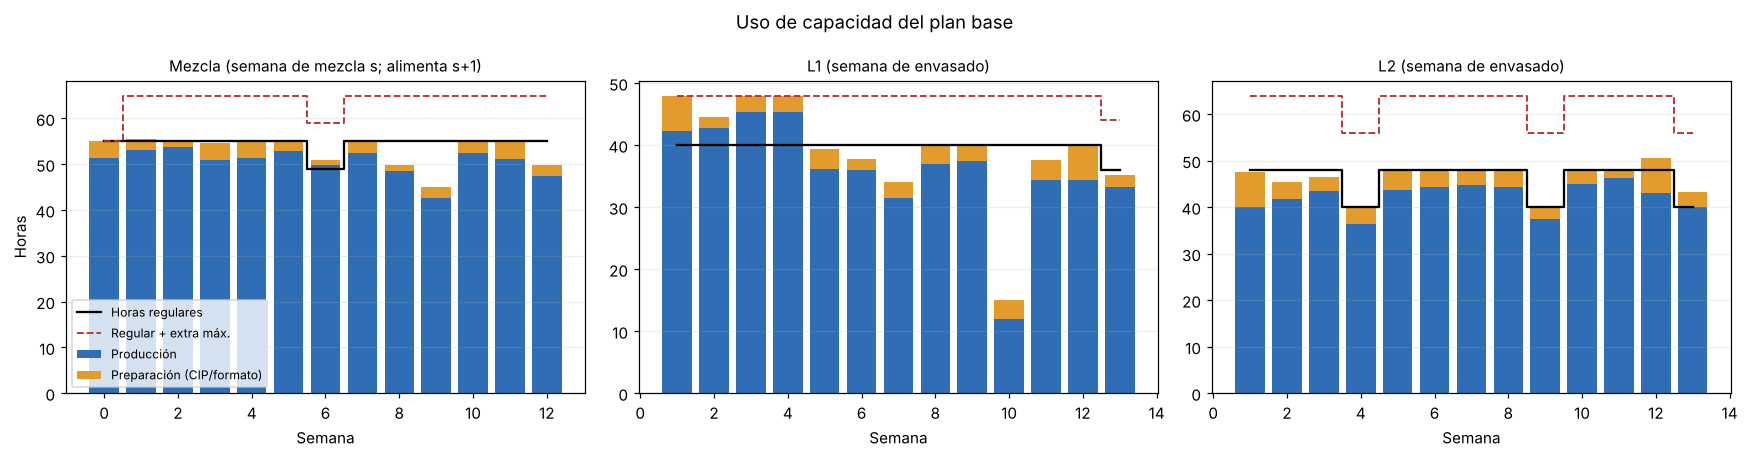

In [ ]:
horas = an.horas_por_recurso(P, sol)
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=False)
for ax, rec in zip(ejes, ["Mezcla", "L1", "L2"]):
    h = horas[horas.Recurso == rec].set_index("Semana").sort_index()
    ax.bar(h.index, h.Horas_produccion, color="#2f6db5", label="Producción")
    ax.bar(h.index, h.Horas_preparacion, bottom=h.Horas_produccion, color="#e39b2d", label="Preparación (CIP/formato)")
    ax.step(h.index, h.Horas_regulares, where="mid", color="black", lw=1.5, label="Horas regulares")
    ax.step(h.index, h.Horas_regulares + [P["Emax_m"][s] if rec == "Mezcla" else P["Emax"][(rec, s)] for s in h.index],
            where="mid", color="#b03030", ls="--", lw=1.2, label="Regular + extra máx.")
    ax.set_title(rec + (" (semana de mezcla s; alimenta s+1)" if rec == "Mezcla" else " (semana de envasado)"), fontsize=10)
    ax.set_xlabel("Semana"); ax.grid(alpha=0.2, axis="y")
ejes[0].set_ylabel("Horas"); ejes[0].legend(fontsize=8, loc="lower left")
plt.suptitle("Uso de capacidad del plan base", fontsize=12)
plt.tight_layout()
plt.savefig(pa.FIGURAS / "uso_capacidad_base.png", dpi=150, bbox_inches="tight")

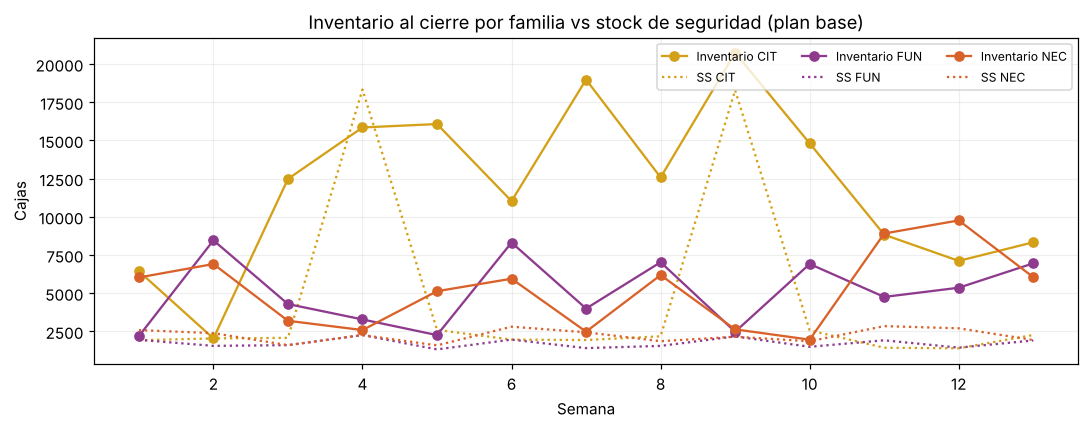

In [ ]:
fam_inv = inv.groupby(lambda i: P["familia"][i]).sum().T
fam_ss = pd.DataFrame({t: {i: P["SS"][(i, t)] for i in P["SKUS"]} for t in P["T"]}).groupby(lambda i: P["familia"][i]).sum().T
fig, ax = plt.subplots(figsize=(10, 4))
colores = {"CIT": "#d4a017", "FUN": "#8e3b8e", "NEC": "#d9622b"}
for f in P["FAMILIAS"]:
    ax.plot(fam_inv.index, fam_inv[f], marker="o", color=colores[f], label=f"Inventario {f}")
    ax.plot(fam_ss.index, fam_ss[f], ls=":", color=colores[f], label=f"SS {f}")
ax.set_xlabel("Semana"); ax.set_ylabel("Cajas"); ax.grid(alpha=0.2)
ax.set_title("Inventario al cierre por familia vs stock de seguridad (plan base)")
ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.savefig(pa.FIGURAS / "inventario_familias_base.png", dpi=150, bbox_inches="tight")

In [ ]:
h = horas.set_index(["Recurso", "Semana"])
mez = h.loc["Mezcla"]
sat = mez[mez.Horas_usadas >= mez.Horas_regulares - 0.5].index.tolist()
print(f"Semanas de mezcla con la mezcladora a plena capacidad regular: {sat} ({len(sat)} de {len(mez)})")
print(f"Horas extra usadas — L1: {h.loc['L1'].Horas_extra.sum():.1f} h | L2: {h.loc['L2'].Horas_extra.sum():.1f} h | "
      f"mezcla: {mez.Horas_extra.sum():.1f} h")
cit = inv.loc["CIT-L05"]
print(f"CIT-L05 promedia {cit.mean():,.0f} cajas en inventario (máximo {cit.max():,.0f}), "
      f"frente a una demanda semanal media de {np.mean([P['d'][('CIT-L05', t)] for t in P['T']]):,.0f}.")

Semanas de mezcla con la mezcladora a plena capacidad regular: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11] (10 de 13)
Horas extra usadas — L1: 28.6 h | L2: 5.9 h | mezcla: 2.8 h
CIT-L05 promedia 7,833 cajas en inventario (máximo 12,890), frente a una demanda semanal media de 2,235.


**Lectura del plan base.**

- **No hay atrasos.** Toda la demanda pronosticada y la cartera en firme se atienden a tiempo.
- La **mezcladora trabaja a plena capacidad regular** en casi todo el horizonte. Las horas extra se
  concentran en L1, que tiene la línea más lenta y la familia CIT-L05, y la mezcla las usa poco.
- El plan **acumula inventario** antes de las semanas con más carga: produce antes para no tener que
  hacerlo con horas extra. La pregunta de decisión (sección 5) explica por qué esa es la palanca más
  barata.
- **CIT-L05 carga con un inventario muy alto.** El modelo intenta acercarse a reservas de 17.540 cajas
  en las semanas 4 y 9, que vienen del dato atípico de la Entrega 1 (sección 3.4).

### 1.2. Efecto de fin de horizonte

La Parte A predijo que, sin restricción terminal, el modelo vaciaría la planta al final del
horizonte. Se comprueba resolviendo el mismo modelo **sin** el punto 7.

,I-B sem.13 con terminal,I-B sem.13 sin terminal,Reserva terminal T_i
NEC-D05,"1,968.00",-532.00,1968
NEC-D15,"3,376.00","-2,000.00",3376
NEC-D30,708.00,-693.00,708
CIT-L05,"3,551.00","-1,717.00",3551
CIT-L15,"4,025.00","-3,093.00",4025
CIT-L30,759.00,-782.00,759
FUN-B05,"3,976.00","-2,544.00",3976
FUN-B15,"2,719.00","-2,424.00",2719
FUN-B30,261.00,-42.00,261


Inventario neto al cierre: 21,343 cajas con terminal vs -13,827 sin terminal.
Producción de las semanas 12-13: 28,483 vs 9,356 cajas.
Atraso acumulado sin terminal: 15,085 cajas-semana; en la semana 13 quedan 13,827 cajas pendientes que pasan a enero.


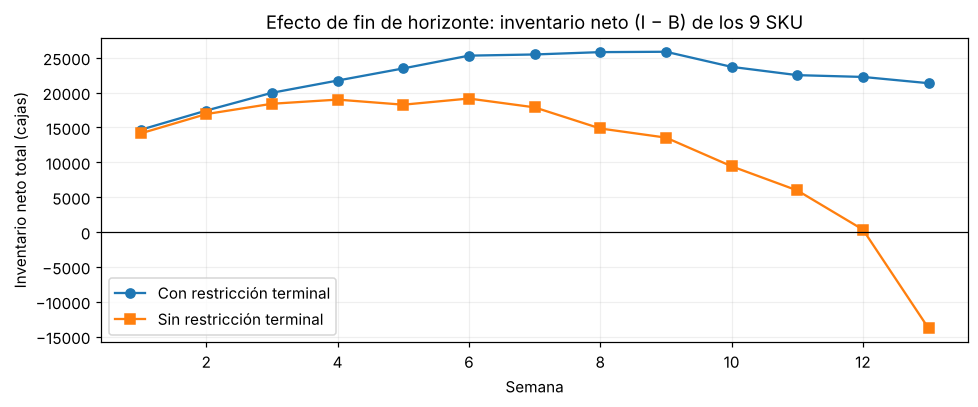

In [ ]:
P_st = pa.construir_parametros(pa.escenario(nombre="Sin restricción terminal", **SENS, restriccion_terminal=False))
m_st, v_st = mo.construir_modelo(P_st)
rep_st = mo.resolver(m_st, P_st, "cbc_sin_terminal.log")
sol_st = mo.extraer_solucion(P_st, v_st)

neto = lambda Px, s, t: sum(s["I"][(i, t)] - s["B"][(i, t)] for i in Px["SKUS"])
comp = pd.DataFrame({"Con terminal": {t: neto(P, sol, t) for t in P["T"]},
                     "Sin terminal": {t: neto(P_st, sol_st, t) for t in P["T"]}})
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(comp.index, comp["Con terminal"], marker="o", label="Con restricción terminal")
ax.plot(comp.index, comp["Sin terminal"], marker="s", label="Sin restricción terminal")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Semana"); ax.set_ylabel("Inventario neto total (cajas)"); ax.grid(alpha=0.2); ax.legend()
ax.set_title("Efecto de fin de horizonte: inventario neto (I − B) de los 9 SKU")
plt.tight_layout(); plt.savefig(pa.FIGURAS / "efecto_fin_horizonte.png", dpi=150, bbox_inches="tight")

ult = pd.DataFrame({"I-B sem.13 con terminal": {i: sol["I"][(i, 13)] - sol["B"][(i, 13)] for i in P["SKUS"]},
                    "I-B sem.13 sin terminal": {i: sol_st["I"][(i, 13)] - sol_st["B"][(i, 13)] for i in P["SKUS"]},
                    "Reserva terminal T_i": P["T_terminal"]})
display(ult.round(0))
prod_final = lambda Px, s: sum(s["x"][(i, t)] for i in Px["SKUS"] for t in (12, 13))
print(f"Inventario neto al cierre: {comp.iloc[-1, 0]:,.0f} cajas con terminal vs {comp.iloc[-1, 1]:,.0f} sin terminal.")
print(f"Producción de las semanas 12-13: {prod_final(P, sol):,.0f} vs {prod_final(P_st, sol_st):,.0f} cajas.")
print(f"Atraso acumulado sin terminal: {sum(sol_st['B'].values()):,.0f} cajas-semana; "
      f"en la semana 13 quedan {sum(sol_st['B'][(i, 13)] for i in P['SKUS']):,.0f} cajas pendientes que pasan a enero.")

**Diagnóstico.** Sin la restricción terminal, el modelo hace exactamente lo que advierte el
enunciado. Al acercarse el fin del horizonte deja de producir, vacía el inventario y termina con
pedidos pendientes. La razón es económica: producir una caja cuesta entre 2.820 y 9.720 CLP, y
atrasarla cuesta solo 1.400 CLP por semana. Como el atraso de la semana 13 se cobra una sola vez y lo
que pasa después no existe para el modelo, "no producir" parece lo más barato.

La restricción $I_{i,13}-B_{i,13}\ge T_i$ corrige ese incentivo: la planta entra a enero con su
reserva más una semana de cobertura y sin deudas con clientes.

## 2. Política de referencia

Sin un punto de comparación, el costo del MIP no se puede interpretar. Se programaron dos reglas
simples que un planificador podría usar en una planilla. Las dos deciden **SKU por SKU**, sin mirar
la capacidad compartida:

- **Lote por lote (L4L).** Cada semana se produce lo justo para cerrar con el stock de seguridad
  (y, en la semana 13, con la reserva terminal).
- **Silver-Meal.** Sobre los requerimientos netos, cada lote cubre las semanas siguientes mientras el
  costo promedio por semana, de preparación más inventario, siga bajando. El costo de preparación
  usado es $74.000\,\tau_f$, más 38.000 CLP en L2.

Después, un **simulador común** les aplica las mismas restricciones físicas del MIP: capacidad de
mezcla con *lead time* de una semana, capacidad de líneas, horas extra hasta su máximo, lote mínimo
y cartera en firme. Si un plan no cabe, se recorta proporcionalmente y lo no producido pasa a la
semana siguiente. Los tres planes se valorizan con **la misma función de costos**.

In [ ]:
politicas = {"MIP (óptimo)": sol,
             "Lote por lote": he.simular(P, he.lote_por_lote(P)),
             "Silver-Meal": he.simular(P, he.silver_meal(P))}
comparacion = pd.DataFrame({k: an.indicadores(P, s) for k, s in politicas.items()})
costos_pol = pd.DataFrame({k: an.costos(P, s) for k, s in politicas.items()}) / 1e6
for nombre in ("Lote por lote", "Silver-Meal"):
    faltante = sum(max(0.0, P["T_terminal"][i] - (politicas[nombre]["I"][(i, 13)] - politicas[nombre]["B"][(i, 13)]))
                   for i in P["SKUS"])
    comparacion.loc["Faltante vs reserva terminal (cajas)", nombre] = faltante
    comparacion.loc["Semanas con capacidad recortada", nombre] = politicas[nombre]["recortes_capacidad"]
comparacion.loc["Faltante vs reserva terminal (cajas)", "MIP (óptimo)"] = 0
comparacion.loc["Semanas con capacidad recortada", "MIP (óptimo)"] = 0
print("Costos (MM CLP):")
display(costos_pol.round(1))
print("Indicadores:")
display(comparacion)
comparacion.to_csv(pa.RESULTADOS / "comparacion_politicas.csv")
costos_pol.to_csv(pa.RESULTADOS / "costos_politicas_MM.csv")

Costos (MM CLP):


,MIP (óptimo),Lote por lote,Silver-Meal
Producción (costo variable),932.90,866.80,900.00
Inventario,27.50,7.60,15.40
Atraso,0.00,4.10,13.10
Déficit de SS,14.50,54.60,69.50
CIP envasado,6.10,10.40,10.10
Cambio de formato,0.60,1.40,1.20
CIP mezcla,2.40,3.50,3.50
Horas extra envasado,5.80,17.10,19.70
Horas extra mezcla,0.30,3.00,4.60
Total,990.10,968.40,"1,037.10"


Indicadores:


,MIP (óptimo),Lote por lote,Silver-Meal
Costo total (MM CLP),990.14,968.40,"1,037.12"
Costo sin costo variable (MM CLP),57.21,101.60,137.16
Fill rate (1 - cajas-semana atrasadas / demanda),1.00,0.98,0.95
SKU-semana con atraso,0,8,16
SKU-semana que cumplen SS (%),95.73,76.92,63.25
Inventario promedio (cajas),"22,262.73","6,119.08","12,504.45"
Rotación (demanda 13 sem / inventario promedio),7.84,28.54,13.97
Cobertura promedio (semanas),1.66,0.46,0.93
Horas extra L1,28.60,36.88,56.69
Horas extra L2,5.90,64.66,60.55


In [ ]:
rel = costos_pol.loc["Total"] - costos_pol.loc["Producción (costo variable)"]
ahorro = {k: rel[k] - rel["MIP (óptimo)"] for k in ("Lote por lote", "Silver-Meal")}
print("Costo relevante (total sin costo variable de producción), MM CLP:")
print(rel.round(1).to_string())
print()
for k, a in ahorro.items():
    print(f"El MIP ahorra {a:,.1f} MM CLP ({100*a/rel[k]:.0f} %) frente a {k}, y además cumple la reserva terminal y "
          f"todas las metas de servicio que {k} no alcanza.")

Costo relevante (total sin costo variable de producción), MM CLP:
MIP (óptimo)     57.20
Lote por lote   101.60
Silver-Meal     137.20

El MIP ahorra 44.4 MM CLP (44 %) frente a Lote por lote, y además cumple la reserva terminal y todas las metas de servicio que Lote por lote no alcanza.
El MIP ahorra 79.9 MM CLP (58 %) frente a Silver-Meal, y además cumple la reserva terminal y todas las metas de servicio que Silver-Meal no alcanza.


**Cómo leer la comparación.** El **costo total** de las heurísticas puede parecer menor, pero es una
ilusión: producen menos y terminan **bajo la reserva terminal** (ver "faltante"). El costo variable
que ahorran es producción que en realidad no se hizo. Por eso la comparación válida es el **costo
relevante**: preparaciones, inventario, atraso, déficit de reserva y horas extra.

Las heurísticas pierden por tres razones:

1. Deciden cada SKU **sin ver la mezcladora compartida**. Cuando la carga se junta, el simulador
   tiene que recortar y aparecen atrasos y déficit de reserva.
2. No **anticipan** producción antes de las semanas saturadas, que es justamente lo que hace el MIP.
3. Usan **casi el doble de preparaciones**, cada una con su CIP.

## 3. Análisis de sensibilidad

Se mueven tres palancas pedidas por el enunciado y dos supuestos propios:

| Palanca | Valores | Cómo se implementa |
| :--- | :--- | :--- |
| Capacidad de mezcla | −10 %, +10 % | Escala la tasa de 2.300 L/h; afecta horas regulares y extra |
| Nivel de servicio objetivo | 90 % y 98 % para todos los SKU (base: 95 % / 92 %) | Cambia $\Phi^{-1}(\alpha)$ y por lo tanto $SS_{it}$ |
| Costo de quiebre | ×0,5, ×2, ×4 | Escala $\pi$ y $\pi^{SS}$ |
| Supuesto: dato atípico | $\hat\sigma$ de CIT-L05 en h=4 y 9 interpolado | Sin modificar la Entrega 1 |
| Supuesto: horas extra de mezcla | prohibidas | Contrafactual para la pregunta de decisión |

In [ ]:
escenarios = [
    ("Mezcla −10 %", dict(factor_capacidad_mezcla=0.9)),
    ("Mezcla +10 %", dict(factor_capacidad_mezcla=1.1)),
    ("Servicio 90 %", dict(nivel_servicio=0.90)),
    ("Servicio 98 %", dict(nivel_servicio=0.98)),
    ("Quiebre ×0,5", dict(factor_penalidad=0.5)),
    ("Quiebre ×2", dict(factor_penalidad=2.0)),
    ("Quiebre ×4", dict(factor_penalidad=4.0)),
    ("σ̂ CIT-L05 sin dato atípico", dict(corregir_sigma_cit_l05=True)),
    ("Sin horas extra de mezcla", dict(sin_extra_mezcla=True)),
]
# La fila "Base" es la solución principal de la sección 1 (tolerancia 0,05 %).
filas = [{"Escenario": "Base", "Estado": rep["estado_cbc"], "Brecha (%)": 100 * rep["brecha"],
          "Tiempo (s)": rep["tiempo_s"], **an.indicadores(P, sol)}]
soluciones = {"Base": (P, sol)}
for k, (nombre, cambios) in enumerate(escenarios, start=1):
    Pk = pa.construir_parametros(pa.escenario(nombre=nombre, **SENS, **cambios))
    mk, vk = mo.construir_modelo(Pk)
    rk = mo.resolver(mk, Pk, f"cbc_sens_{k:02d}.log")
    sk = mo.extraer_solucion(Pk, vk)
    soluciones[nombre] = (Pk, sk)
    ind = an.indicadores(Pk, sk)
    filas.append({"Escenario": nombre, "Estado": rk["estado_cbc"], "Brecha (%)": 100 * rk["brecha"],
                  "Tiempo (s)": rk["tiempo_s"], **ind})
    print(f"{nombre:<30} {rk['estado_cbc']:<48} {rk['tiempo_s']:6.1f} s", flush=True)
sens = pd.DataFrame(filas).set_index("Escenario")
sens.to_csv(pa.RESULTADOS / "sensibilidad.csv")

Mezcla −10 %                   Optimal solution found (within gap tolerance)      81.6 s
Mezcla +10 %                   Optimal solution found (within gap tolerance)       8.2 s
Servicio 90 %                  Optimal solution found (within gap tolerance)      83.7 s
Servicio 98 %                  Optimal solution found (within gap tolerance)     114.9 s
Quiebre ×0,5                   Optimal solution found (within gap tolerance)     100.1 s
Quiebre ×2                     Optimal solution found (within gap tolerance)      72.0 s
Quiebre ×4                     Optimal solution found (within gap tolerance)     112.1 s
σ̂ CIT-L05 sin dato atípico    Optimal solution found (within gap tolerance)     262.7 s
Sin horas extra de mezcla      Optimal solution found (within gap tolerance)      90.9 s


,Costo total,Costo relevante,Inventario medio,HE L1,HE L2,HE mezcla,Fill rate,% SS cumplido,Brecha %,Δ costo relevante vs base
Escenario,,,,,,,,,,
Base,990.14,57.21,"22,262.73",28.60,5.90,2.81,1.00,95.73,0.05,0.00
Mezcla −10 %,997.01,64.09,"22,122.24",22.24,6.46,53.58,1.00,95.73,0.24,6.88
Mezcla +10 %,989.67,56.75,"22,675.70",28.60,1.00,0.00,1.00,95.73,0.24,-0.46
Servicio 90 %,973.17,45.53,"21,496.91",28.13,5.05,1.74,1.00,95.73,0.21,-11.68
Servicio 98 %,"1,016.82",73.55,"23,616.67",32.00,9.19,10.06,1.00,94.87,0.19,16.34
"Quiebre ×0,5",981.88,48.95,"20,248.66",1.57,1.81,4.41,1.00,92.31,0.25,-8.26
Quiebre ×2,"1,004.41",71.49,"22,335.21",32.00,5.90,3.51,1.00,95.73,0.19,14.28
Quiebre ×4,"1,026.65",80.71,"25,105.64",46.67,3.97,12.05,1.00,95.73,0.24,23.50
σ̂ CIT-L05 sin dato atípico,966.92,34.00,"19,048.33",0.00,4.70,4.79,1.00,98.29,0.24,-23.21


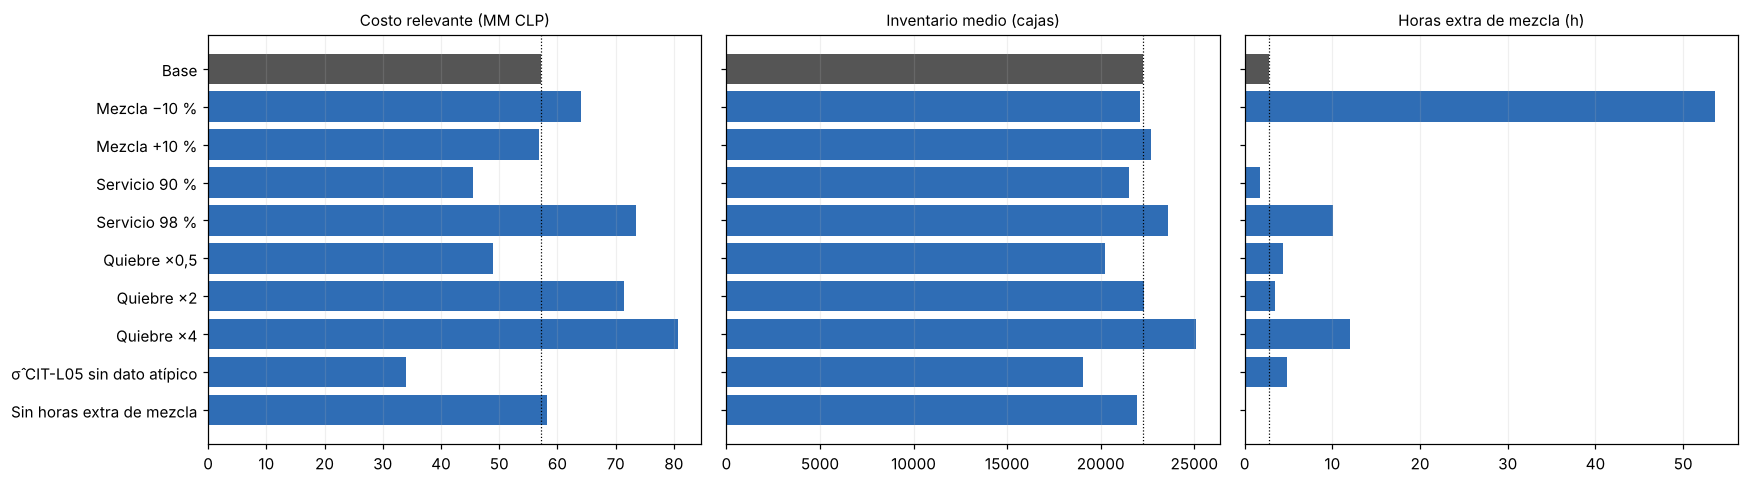

In [ ]:
cols = ["Costo total (MM CLP)", "Costo sin costo variable (MM CLP)", "Inventario promedio (cajas)",
        "Horas extra L1", "Horas extra L2", "Horas extra mezcla", "Fill rate (1 - cajas-semana atrasadas / demanda)",
        "SKU-semana que cumplen SS (%)", "Brecha (%)"]
vista = sens[cols].copy()
vista.columns = ["Costo total", "Costo relevante", "Inventario medio", "HE L1", "HE L2", "HE mezcla",
                 "Fill rate", "% SS cumplido", "Brecha %"]
vista["Δ costo relevante vs base"] = vista["Costo relevante"] - vista.loc["Base", "Costo relevante"]
display(vista.round(2))

fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
orden = vista.index.tolist()
for ax, col, titulo in zip(ejes, ["Costo relevante", "Inventario medio", "HE mezcla"],
                           ["Costo relevante (MM CLP)", "Inventario medio (cajas)", "Horas extra de mezcla (h)"]):
    colores_b = ["#555555" if n == "Base" else "#2f6db5" for n in orden]
    ax.barh(orden, vista[col], color=colores_b)
    ax.axvline(vista.loc["Base", col], color="black", lw=0.8, ls=":")
    ax.set_title(titulo, fontsize=10); ax.invert_yaxis(); ax.grid(alpha=0.2, axis="x")
    if ax is not ejes[0]:
        ax.set_yticklabels([])
plt.tight_layout(); plt.savefig(pa.FIGURAS / "sensibilidad.png", dpi=150, bbox_inches="tight")

In [ ]:
b = vista.loc["Base"]
def d(n, c="Costo relevante"): return vista.loc[n, c] - b[c]
print("Lectura de la sensibilidad (Δ respecto del base; brecha de cada corrida ≤ "
      f"{vista['Brecha %'].max():.2f} % del costo total ≈ {vista['Brecha %'].max()/100*b['Costo total']:.1f} MM CLP):")
print(f"• Mezcla −10 %: costo relevante {d('Mezcla −10 %'):+.1f} MM; horas extra de mezcla "
      f"{b['HE mezcla']:.1f} → {vista.loc['Mezcla −10 %','HE mezcla']:.1f} h. Con menos mezcla, la anticipación no alcanza y hay que pagar horas extra.")
print(f"• Mezcla +10 %: costo relevante {d('Mezcla +10 %'):+.1f} MM; horas extra de mezcla → {vista.loc['Mezcla +10 %','HE mezcla']:.1f} h.")
print(f"• Servicio 90 % / 98 %: {d('Servicio 90 %'):+.1f} / {d('Servicio 98 %'):+.1f} MM; inventario medio "
      f"{vista.loc['Servicio 90 %','Inventario medio']:,.0f} / {vista.loc['Servicio 98 %','Inventario medio']:,.0f} cajas "
      f"(base {b['Inventario medio']:,.0f}).")
print(f"• Quiebre ×0,5 / ×2 / ×4: {d('Quiebre ×0,5'):+.1f} / {d('Quiebre ×2'):+.1f} / {d('Quiebre ×4'):+.1f} MM. "
      f"Fill rate mínimo entre los tres: {vista.loc[['Quiebre ×0,5','Quiebre ×2','Quiebre ×4'],'Fill rate'].min():.3f}; "
      "incluso con la mitad de la penalidad, el modelo no elige atrasar.")
for n in vista.index[1:]:
    tolerancia = (vista.loc[n, "Brecha %"] / 100 * vista.loc[n, "Costo total"]
                  + vista.loc["Base", "Brecha %"] / 100 * vista.loc["Base", "Costo total"])
    if abs(vista.loc[n, "Δ costo relevante vs base"]) < tolerancia:
        print(f"  (no concluyente) {n}: |Δ| = {abs(vista.loc[n, 'Δ costo relevante vs base']):.2f} MM es menor que "
              f"la suma de las brechas ({tolerancia:.2f} MM).")
print(f"• Dato atípico de CIT-L05: interpolar su σ̂ baja el costo relevante en {-d('σ̂ CIT-L05 sin dato atípico'):.1f} MM "
      f"y el inventario medio en {b['Inventario medio'] - vista.loc['σ̂ CIT-L05 sin dato atípico','Inventario medio']:,.0f} cajas. "
      "Ese es el costo de no corregir el dato en la Entrega 1.")
print(f"• Sin horas extra de mezcla: {d('Sin horas extra de mezcla'):+.1f} MM.")

Lectura de la sensibilidad (Δ respecto del base; brecha de cada corrida ≤ 0.25 % del costo total ≈ 2.5 MM CLP):
• Mezcla −10 %: costo relevante +6.9 MM; horas extra de mezcla 2.8 → 53.6 h. Con menos mezcla, la anticipación no alcanza y hay que pagar horas extra.
• Mezcla +10 %: costo relevante -0.5 MM; horas extra de mezcla → 0.0 h.
• Servicio 90 % / 98 %: -11.7 / +16.3 MM; inventario medio 21,497 / 23,617 cajas (base 22,263).
• Quiebre ×0,5 / ×2 / ×4: -8.3 / +14.3 / +23.5 MM. Fill rate mínimo entre los tres: 1.000; incluso con la mitad de la penalidad, el modelo no elige atrasar.
  (no concluyente) Mezcla +10 %: |Δ| = 0.46 MM es menor que la suma de las brechas (2.86 MM).
  (no concluyente) Sin horas extra de mezcla: |Δ| = 1.04 MM es menor que la suma de las brechas (2.62 MM).
• Dato atípico de CIT-L05: interpolar su σ̂ baja el costo relevante en 23.2 MM y el inventario medio en 3,214 cajas. Ese es el costo de no corregir el dato en la Entrega 1.
• Sin horas extra de mezcla: +1.0 MM.


**Conclusiones de la sensibilidad.**

- **La capacidad de mezcla es asimétrica.** Perder el 10 % obliga a comprar muchas horas extra de
  mezcla, porque la anticipación ya no alcanza. Ganar el 10 % casi no ahorra, y la diferencia queda
  dentro de la brecha del solver: con más mezcla, el límite pasa a ser L2 y las preparaciones.
- **El nivel de servicio se paga en inventario.** Llevar todos los SKU al 98 % sube $\Phi^{-1}$ de
  1,645 a 2,054 (+25 % de reserva), y en FUN, desde 1,405 (+46 %). El inventario medio y el costo
  relevante suben en consecuencia. Bajar al 90 % hace lo contrario.
- **El atraso nunca es la opción elegida**, ni siquiera con la mitad de la penalidad: el fill rate
  es 1 en todos los escenarios con reserva terminal. Atrasar una
  caja cuesta 1.400 CLP por semana más el déficit de reserva, mientras que guardarla una semana cuesta
  95 CLP.
- **El dato atípico tiene un costo cuantificable.** Es el cambio más grande entre todos los
  escenarios: elimina las horas extra de L1 y buena parte del inventario de CIT-L05. Se informa
  para que la gerencia sepa cuánto cuesta no corregirlo en la Entrega 1.
- Una Δ menor que la brecha de su corrida (columna "Brecha %") **no es concluyente**: el solver no
  alcanza a distinguir esos dos planes.

Los valores exactos de cada Δ están en la salida de la celda anterior y en `resultados/sensibilidad.csv`.

## 4. Cuadro de mando del plan base

In [ ]:
c = pd.Series(an.costos(P, sol)) / 1e6
desglose = c.drop("Total").sort_values(ascending=False).to_frame("MM CLP")
desglose["% del total"] = 100 * desglose["MM CLP"] / c["Total"]
desglose["% del costo relevante"] = 100 * desglose["MM CLP"] / (c["Total"] - c["Producción (costo variable)"])
desglose.loc["Producción (costo variable)", "% del costo relevante"] = np.nan
desglose.loc["Total"] = [c["Total"], 100, np.nan]
print("Costo total desglosado:")
display(desglose.round(2))

ind = pd.Series(an.indicadores(P, sol))
print("Indicadores de servicio, inventario y capacidad:")
display(ind.to_frame("Plan base"))
desglose.to_csv(pa.RESULTADOS / "cuadro_mando_costos.csv")
ind.to_frame("Plan base").to_csv(pa.RESULTADOS / "cuadro_mando_indicadores.csv")

Costo total desglosado:


,MM CLP,% del total,% del costo relevante
Producción (costo variable),932.93,94.22,NaN
Inventario,27.49,2.78,48.06
Déficit de SS,14.53,1.47,25.40
CIP envasado,6.08,0.61,10.63
Horas extra envasado,5.80,0.59,10.13
CIP mezcla,2.40,0.24,4.19
Cambio de formato,0.57,0.06,1.00
Horas extra mezcla,0.34,0.03,0.59
Atraso,0.00,0.00,0.00
Total,990.14,100.00,NaN


Indicadores de servicio, inventario y capacidad:


,Plan base
Costo total (MM CLP),990.14
Costo sin costo variable (MM CLP),57.21
Fill rate (1 - cajas-semana atrasadas / demanda),1.00
SKU-semana con atraso,0
SKU-semana que cumplen SS (%),95.73
Inventario promedio (cajas),"22,262.73"
Rotación (demanda 13 sem / inventario promedio),7.84
Cobertura promedio (semanas),1.66
Horas extra L1,28.60
Horas extra L2,5.90


In [ ]:
servicio_sku = pd.DataFrame({
    "Demanda 13 sem.": {i: sum(P["d"][(i, t)] for t in P["T"]) for i in P["SKUS"]},
    "Producción vendible": {i: sum(P["rend"][i] * sol["x"][(i, t)] for t in P["T"]) for i in P["SKUS"]},
    "Atraso (cajas-sem.)": {i: sum(sol["B"][(i, t)] for t in P["T"]) for i in P["SKUS"]},
    "Semanas bajo SS": {i: sum(1 for t in P["T"] if sol["I"][(i, t)] - sol["B"][(i, t)] < P["SS"][(i, t)] - 0.5) for i in P["SKUS"]},
    "Inventario medio": {i: np.mean([sol["I"][(i, t)] for t in P["T"]]) for i in P["SKUS"]},
})
servicio_sku["Rotación (13 sem.)"] = servicio_sku["Demanda 13 sem."] / servicio_sku["Inventario medio"]
servicio_sku["Preparaciones"] = {i: sum(sol["y"][(i, t)] for t in P["T"]) for i in P["SKUS"]}
print("Servicio e inventario por SKU:")
display(servicio_sku.round(1))
servicio_sku.to_csv(pa.RESULTADOS / "cuadro_mando_sku.csv")

Servicio e inventario por SKU:


,Demanda 13 sem.,Producción vendible,Atraso (cajas-sem.),Semanas bajo SS,Inventario medio,Rotación (13 sem.),Preparaciones
NEC-D05,"15,309.80","16,253.80",0.00,1,"1,849.90",8.30,6
NEC-D15,"26,533.60","26,747.60",0.00,0,"2,584.40",10.30,9
NEC-D30,"6,415.30","6,784.30",0.00,0,781.20,8.20,6
CIT-L05,"29,055.00","31,389.00",0.00,2,"7,832.60",3.70,6
CIT-L15,"34,665.90","37,408.90",0.00,0,"2,727.80",12.70,7
CIT-L30,"6,472.00","6,976.00",0.00,0,"1,387.20",4.70,5
FUN-B05,"33,081.90","34,922.90",0.00,0,"2,468.60",13.40,9
FUN-B15,"21,772.60","23,230.60",0.00,0,"2,195.30",9.90,7
FUN-B30,"1,335.00","1,441.00",0.00,2,435.50,3.10,4


Utilización de horas regulares por recurso y semana (%), mezcla en semana de mezcla s:


Semana,0,1,2,3,4,5,6,7,8,9,10,11,12,13
Recurso,,,,,,,,,,,,,,
L1,NaN,100.00,100.00,100.00,100.00,98.00,95.00,85.00,100.00,100.00,38.00,94.00,100.00,98.00
L2,NaN,99.00,95.00,97.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00
Mezcla,100.00,100.00,100.00,99.00,100.00,100.00,100.00,100.00,91.00,82.00,100.00,100.00,91.00,NaN


Horas extra por recurso y semana:


Semana,0,1,2,3,4,5,6,7,8,9,10,11,12,13
Recurso,,,,,,,,,,,,,,
L1,NaN,8.00,4.60,8.00,8.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
L2,NaN,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2.60,3.30
Mezcla,0.00,0.50,0.00,0.00,0.00,0.30,2.00,0.00,0.00,0.00,0.00,0.00,0.00,NaN


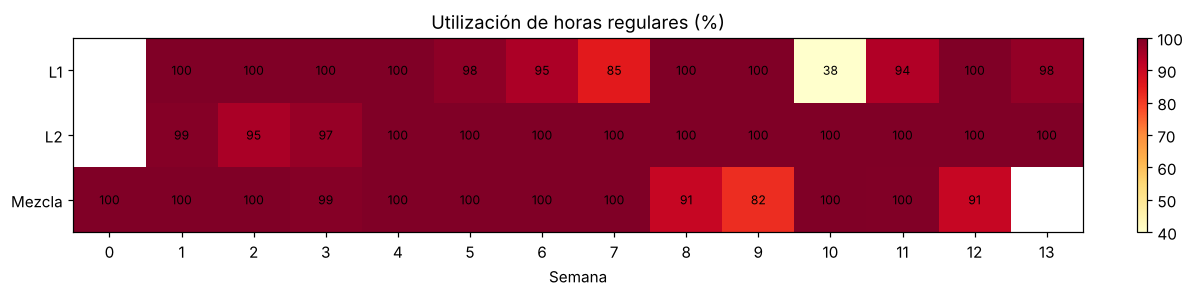

In [ ]:
util = horas.pivot(index="Recurso", columns="Semana", values="Utilizacion_regular")
extra = horas.pivot(index="Recurso", columns="Semana", values="Horas_extra")
print("Utilización de horas regulares por recurso y semana (%), mezcla en semana de mezcla s:")
display((100 * util).round(0))
print("Horas extra por recurso y semana:")
display(extra.round(1))
util.to_csv(pa.RESULTADOS / "utilizacion_recursos.csv")
extra.to_csv(pa.RESULTADOS / "horas_extra_semana.csv")

fig, ax = plt.subplots(figsize=(11, 2.8))
im = ax.imshow(100 * util.values, cmap="YlOrRd", vmin=40, vmax=100, aspect="auto")
ax.set_yticks(range(len(util.index)), util.index); ax.set_xticks(range(len(util.columns)), util.columns)
for (r, k), val in np.ndenumerate(100 * util.values):
    if not np.isnan(val):
        ax.text(k, r, f"{val:.0f}", ha="center", va="center", fontsize=8)
ax.set_xlabel("Semana"); ax.set_title("Utilización de horas regulares (%)")
plt.colorbar(im, ax=ax, fraction=0.02)
plt.tight_layout(); plt.savefig(pa.FIGURAS / "utilizacion_recursos.png", dpi=150, bbox_inches="tight")

## 5. Pregunta de decisión

> *La capacidad de mezcla está al límite en varias semanas del horizonte. ¿Conviene pagar horas extra,
> adelantar producción a inventario, o aceptar atraso penalizado?*

La respuesta sale de comparar el **costo marginal de cubrir una caja más** en una semana con la
mezcladora saturada, por cada una de las tres vías.

| Vía | Costo marginal por caja | Deducción |
| :--- | :--- | :--- |
| Hora extra de mezcla | $121.000\cdot L^{ef}_i/2.300$ | Una hora extra prepara 2.300 L |
| Adelantar $k$ semanas | $95\,k$ | Costo de inventario por caja y semana |
| Atrasar 1 semana | $1.400$ (+1.400 si deja la reserva bajo SS) | Penalidad de atraso + déficit de SS |

A esto se suma la hora extra de **envasado** si la línea también está llena: 168.000 CLP/h dividido
por la tasa de la línea.

In [ ]:
marg = []
for i in ["NEC-D05", "NEC-D15", "NEC-D30"]:
    fmt = {"NEC-D05": "0,5 L", "NEC-D15": "1,5 L", "NEC-D30": "3,0 L"}[i]
    he_mez = P["c_extra_m"] * P["litros_ef"][i] / P["tasa_mezcla"][1]
    he_lin = P["c_extra"][P["linea"][i]] / P["tasa"][i]
    marg.append({"Formato": fmt, "HE mezcla (CLP/caja)": he_mez, "HE envasado (CLP/caja)": he_lin,
                 "Adelantar 1 sem. (CLP/caja)": P["h"][i],
                 "Atrasar 1 sem. (CLP/caja)": P["pi"][i], "Atrasar bajo SS (CLP/caja)": P["pi"][i] + P["pi_ss"][i],
                 "Semanas de anticipación que igualan la HE de mezcla": he_mez / P["h"][i]})
marginal = pd.DataFrame(marg).set_index("Formato")
display(marginal.round(1))
marginal.to_csv(pa.RESULTADOS / "decision_costos_marginales.csv")

,HE mezcla (CLP/caja),HE envasado (CLP/caja),Adelantar 1 sem. (CLP/caja),Atrasar 1 sem. (CLP/caja),Atrasar bajo SS (CLP/caja),Semanas de anticipación que igualan la HE de mezcla
Formato,,,,,,
"0,5 L",319.30,933.30,95.00,"1,400.00","2,800.00",3.40
"1,5 L",474.90,800.00,95.00,"1,400.00","2,800.00",5.00
"3,0 L",633.10,"1,292.30",95.00,"1,400.00","2,800.00",6.70


#### 5.1. Lo que confirma el modelo: precios sombra de la mezcla

Se fijan las preparaciones del plan óptimo y se resuelve el problema lineal que queda. El **dual**
de la restricción de capacidad de mezcla de la semana $s$ es lo que valdría, en CLP, una hora más
de mezcla esa semana. Si el dual es menor que 121.000 CLP, comprar horas extra no conviene: el modelo
tiene una forma más barata de liberar esa hora, que es anticipar producción.

,Precio sombra mezcla (CLP/h),Horas extra de mezcla usadas,Utilización regular (%)
Semana de mezcla,,,
0,"103,408.00",0.00,100.00
1,"121,000.00",1.00,100.00
2,"88,672.00",0.00,100.00
3,-0.00,0.00,99.00
4,"85,687.00",0.00,100.00
5,"121,000.00",0.00,100.00
6,"121,000.00",2.00,100.00
7,-0.00,0.00,100.00
8,-0.00,0.00,91.00


Estado del LP con preparaciones fijas: Optimal


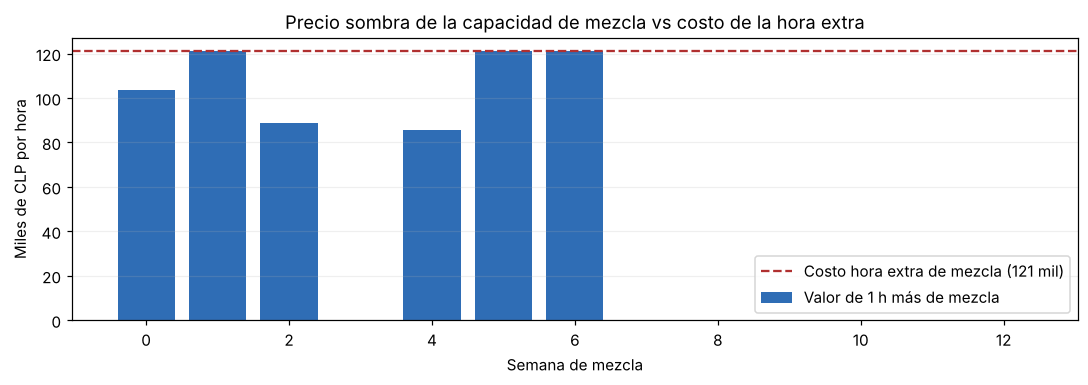

In [ ]:
sombra = mo.precios_sombra_mezcla(P, sol)
duales = pd.DataFrame({
    "Precio sombra mezcla (CLP/h)": {s: sombra["duales"][("mezcla", s)] for s in P["SEMANAS_MEZCLA"]},
    "Horas extra de mezcla usadas": {s: sol["Em"][s] for s in P["SEMANAS_MEZCLA"]},
    "Utilización regular (%)": {s: 100 * util.loc["Mezcla", s] for s in P["SEMANAS_MEZCLA"]},
})
duales.index.name = "Semana de mezcla"
display(duales.round(0))
duales.to_csv(pa.RESULTADOS / "decision_precios_sombra.csv")
print("Estado del LP con preparaciones fijas:", sombra["estado"])

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(duales.index, duales["Precio sombra mezcla (CLP/h)"] / 1000, color="#2f6db5", label="Valor de 1 h más de mezcla")
ax.axhline(P["c_extra_m"] / 1000, color="#b03030", ls="--", label="Costo hora extra de mezcla (121 mil)")
ax.set_xlabel("Semana de mezcla"); ax.set_ylabel("Miles de CLP por hora"); ax.grid(alpha=0.2, axis="y")
ax.legend(); ax.set_title("Precio sombra de la capacidad de mezcla vs costo de la hora extra")
plt.tight_layout(); plt.savefig(pa.FIGURAS / "precios_sombra_mezcla.png", dpi=150, bbox_inches="tight")

In [ ]:
usadas = duales[duales["Horas extra de mezcla usadas"] > 0.05]
bajo = duales[(duales["Precio sombra mezcla (CLP/h)"] > 1) & (duales["Precio sombra mezcla (CLP/h)"] < P["c_extra_m"] - 1)]
inv_total = an.tabla(P, sol, "I").sum()
print(f"Semanas con horas extra de mezcla: {usadas.index.tolist()} "
      f"({usadas['Horas extra de mezcla usadas'].sum():.1f} h en total, {usadas['Horas extra de mezcla usadas'].sum()*P['c_extra_m']/1e6:.2f} MM CLP).")
print(f"Semanas con mezcla saturada donde la hora vale menos que la hora extra (se resuelve anticipando): {bajo.index.tolist()}")
print(f"Inventario total al cierre por semana (cajas): {inv_total.round(0).astype(int).tolist()}")
sin_he = vista.loc["Sin horas extra de mezcla", "Costo relevante"] - vista.loc["Base", "Costo relevante"]
brecha_mm = vista.loc["Sin horas extra de mezcla", "Brecha %"] / 100 * vista.loc["Sin horas extra de mezcla", "Costo total"]
print(f"Prohibir por completo las horas extra de mezcla cambia el costo relevante en {sin_he:+.2f} MM CLP "
      f"(brecha de esa corrida: {brecha_mm:.2f} MM). En el plan base, las horas extra de mezcla son una palanca marginal.")
print(f"Atraso en el plan óptimo: {sum(sol['B'].values()):,.0f} cajas-semana, incluso con la penalidad a la mitad "
      f"({sens.loc['Quiebre ×0,5','SKU-semana con atraso']:.0f} SKU-semana con atraso).")

Semanas con horas extra de mezcla: [1, 5, 6] (2.8 h en total, 0.34 MM CLP).
Semanas con mezcla saturada donde la hora vale menos que la hora extra (se resuelve anticipando): [0, 2, 4]
Inventario total al cierre por semana (cajas): [14658, 17415, 19968, 21724, 23464, 25297, 25464, 25800, 25853, 23687, 22499, 22242, 21343]
Prohibir por completo las horas extra de mezcla cambia el costo relevante en +1.04 MM CLP (brecha de esa corrida: 2.13 MM). En el plan base, las horas extra de mezcla son una palanca marginal.
Atraso en el plan óptimo: 0 cajas-semana, incluso con la penalidad a la mitad (0 SKU-semana con atraso).


#### 5.2. Respuesta

**Primero, adelantar producción a inventario.** Guardar una caja una semana cuesta 95 CLP. La hora
extra de mezcla equivale a entre unos 320 CLP (0,5 L) y 630 CLP (3,0 L) por caja. Anticipar es más
barato mientras la caja no deba esperar más de unas **3 a 7 semanas**, según el formato (tabla de
costos marginales). Por eso el plan mantiene la mezcladora llena desde la primera semana y acumula
producto terminado durante la primera mitad del horizonte. Ese inventario se consume en las semanas
previas al peak, cuando la demanda supera lo que la mezcla puede preparar.

**Segundo, horas extra, pero solo donde anticipar ya no alcanza.** Si una semana saturada no tiene
semanas anteriores libres para adelantar, como el inicio del horizonte o las semanas alrededor de la mantención de la semana 6,
el precio sombra de la mezcla sube hasta 121.000 CLP/h y recién ahí se compra la hora. En las demás
semanas saturadas, el precio sombra queda bajo 121.000: la restricción está activa, pero resolverla
anticipando sale más barato que pagar horas extra.

**Nunca atraso.** Atrasar cuesta 1.400 CLP por caja y semana, y 2.800 si además deja la reserva
bajo el SS. Es 15 a 30 veces más caro que anticipar y de 2 a 9 veces más caro que la hora extra. El
plan óptimo no atrasa ninguna caja, y la sensibilidad muestra que eso se mantiene aun con la mitad
de la penalidad.

Las cifras exactas (horas extra usadas, precios sombra por semana, curva de inventario y costo de
prohibir las horas extra) están en la salida de las celdas anteriores y en `resultados/decision_*.csv`.

# Entrega 2 — Parte C: El puente hacia la Entrega Final

Del plan óptimo de la Parte B se **extrae y congela el programa de la semana 12** (lunes 14/12/2026):

- qué SKU se producen, en qué cantidad y en qué línea;
- cuántas horas de preparación supuso el modelo en cada recurso.

Ese último número es el que la Entrega Final va a poner a prueba. Allí la secuencia real, con la
matriz CIP asimétrica, dirá si las horas reservadas alcanzaban.

Este notebook **no vuelve a resolver** el modelo. Lee la solución guardada por la Parte B en
`resultados/solucion_base.json`, para que el programa congelado sea exactamente el del plan
reportado.

In [ ]:
P = pa.construir_parametros(pa.Escenario())
sol = an.cargar_solucion(pa.RESULTADOS / "solucion_base.json")
assert abs(an.costos(P, sol)["Total"] - float(pd.read_csv(pa.RESULTADOS / "resolucion_base.csv", index_col=0)
                                                .loc["Valor objetivo (CLP)"].iloc[0].replace(",", ""))) < 1.0
print("Solución base cargada y verificada contra el valor objetivo de la Parte B.")
T12 = pa.SEMANA_FOCAL
print("Semana focal:", T12, "| lunes", P["fecha"][T12])

Paquete cargado desde: /home/claude/gdbs2/Entrega 2
PuLP 2.9.0 | solvers disponibles: ['PULP_CBC_CMD']
Solución base cargada y verificada contra el valor objetivo de la Parte B.
Semana focal: 12 | lunes 2026-12-14


## 1. Programa de producción de la semana 12

Para cada SKU se informa la producción **bruta**, que es lo que la línea debe envasar, y la
**vendible**, que es lo que queda después de la merma heredada de la Entrega 1. También se muestra
la cartera en firme que esa producción debe cubrir.

In [ ]:
com = pa.cargar_datos()["compromisos"]
filas = []
for i in P["SKUS"]:
    x = sol["x"][(i, T12)]
    filas.append({
        "SKU": i, "Familia": P["familia"][i], "Línea": P["linea"][i],
        "Producción bruta (cajas)": round(x),
        "Producción vendible (cajas)": round(P["rend"][i] * x),
        "Cartera en firme (cajas)": P["C"][i],
        "Órdenes": int((com.sku == i).sum()),
        "Holgura sobre cartera (cajas)": round(P["rend"][i] * x - P["C"][i]),
        "Horas de envasado": x / P["tasa"][i],
        "Litros de jarabe (mezclados en sem. 11)": P["litros_ef"][i] * x,
    })
programa = pd.DataFrame(filas).set_index("SKU").sort_values(["Línea", "Familia"])
display(programa.round(1))
assert (programa["Holgura sobre cartera (cajas)"] >= -0.5).all(), "La producción no cubre la cartera en firme."
programa.to_csv(pa.RESULTADOS / "programa_semana12.csv")
print("Los 9 SKU cubren su cartera en firme. Total bruto:", f"{programa['Producción bruta (cajas)'].sum():,.0f} cajas.")

,Familia,Línea,Producción bruta (cajas),Producción vendible (cajas),Cartera en firme (cajas),Órdenes,Holgura sobre cartera (cajas),Horas de envasado,Litros de jarabe (mezclados en sem. 11)
SKU,,,,,,,,,
CIT-L05,CIT,L1,855,839,839.00,2,0,4.80,"5,191.40"
FUN-B05,FUN,L1,2606,2556,"1,340.00",2,1216,14.50,"15,815.80"
NEC-D05,NEC,L1,2712,2660,898.00,2,1762,15.10,"16,460.70"
CIT-L15,CIT,L2,3793,3675,"1,026.00",2,2649,18.10,"34,246.70"
CIT-L30,CIT,L2,217,210,157.00,1,53,1.70,"2,606.20"
FUN-B15,FUN,L2,2546,2467,860.00,2,1607,12.10,"22,987.80"
FUN-B30,FUN,L2,68,66,66.00,1,0,0.50,819.80
NEC-D15,NEC,L2,1736,1682,"1,320.00",2,362,8.30,"15,675.30"
NEC-D30,NEC,L2,323,313,313.00,1,0,2.50,"3,887.60"


Los 9 SKU cubren su cartera en firme. Total bruto: 14,856 cajas.


## 2. Horas de preparación supuestas por el modelo

En la semana 12 el modelo reservó, por cada campaña de familia abierta en una línea, el tiempo
esperado de entrada $\tau_f$. En L2 agregó 0,6 h por cada cambio de formato dentro de una familia. En
la mezcladora reservó 1,2 h de CIP por cada familia mezclada en la semana 11.

In [ ]:
prep = []
for l in P["LINEAS"]:
    fams = [f for f in P["FAMILIAS"] if sol["w"].get((l, f, T12), 0) > 0.5]
    cip = sum(P["tau_cip"][f] for f in fams)
    fmt = sum(P["horas_formato"]["L2"] * sol["fc"][(f, T12)] for f in P["FAMILIAS"]) if l == "L2" else 0.0
    prod = sum(sol["x"][(i, T12)] / P["tasa"][i] for i in P["skus_linea"][l])
    prep.append({"Recurso": l, "Familias activas": ", ".join(fams), "Horas CIP supuestas (Σ τ_f)": cip,
                 "Cambios de formato": sum(sol["fc"][(f, T12)] for f in P["FAMILIAS"]) if l == "L2" else 0,
                 "Horas de cambio de formato": fmt, "Horas de preparación totales": cip + fmt,
                 "Horas de producción": prod, "Horas regulares": P["H"][(l, T12)],
                 "Horas extra planificadas": sol["E"][(l, T12)]})
s11 = T12 - 1
fams_m = [f for f in P["FAMILIAS"] if sol["z"][(f, s11)] > 0.5]
prep.append({"Recurso": "Mezcla (sem. 11)", "Familias activas": ", ".join(fams_m),
             "Horas CIP supuestas (Σ τ_f)": P["cip_mezcla"][s11] * len(fams_m), "Cambios de formato": 0,
             "Horas de cambio de formato": 0.0, "Horas de preparación totales": P["cip_mezcla"][s11] * len(fams_m),
             "Horas de producción": sum(sol["V"][(f, s11)] for f in P["FAMILIAS"]) / P["tasa_mezcla"][s11],
             "Horas regulares": P["Hm"][s11], "Horas extra planificadas": sol["Em"][s11]})
preparacion = pd.DataFrame(prep).set_index("Recurso")
preparacion["Holgura (h)"] = (preparacion["Horas regulares"] + preparacion["Horas extra planificadas"]
                              - preparacion["Horas de producción"] - preparacion["Horas de preparación totales"])
display(preparacion.round(2))
preparacion.to_csv(pa.RESULTADOS / "preparacion_semana12.csv")
for rec, fila in preparacion.iterrows():
    holgura = max(0.0, round(fila["Holgura (h)"], 2))
    print(f"{rec}: el modelo supuso {fila['Horas de preparación totales']:.1f} h de preparación "
          f"y deja {holgura:.1f} h de holgura" + (" (recurso lleno: cualquier hora adicional de limpieza exige horas extra)." if holgura < 0.5 else "."))

,Familias activas,Horas CIP supuestas (Σ τ_f),Cambios de formato,Horas de cambio de formato,Horas de preparación totales,Horas de producción,Horas regulares,Horas extra planificadas,Holgura (h)
Recurso,,,,,,,,,
L1,"CIT, FUN, NEC",5.70,0.00,0.00,5.70,34.30,40.00,0.00,-0.00
L2,"CIT, FUN, NEC",5.70,3.00,1.80,7.50,43.13,48.00,2.63,-0.00
Mezcla (sem. 11),"CIT, FUN, NEC",3.60,0.00,0.00,3.60,51.17,55.00,0.00,0.23


L1: el modelo supuso 5.7 h de preparación y deja 0.0 h de holgura (recurso lleno: cualquier hora adicional de limpieza exige horas extra).
L2: el modelo supuso 7.5 h de preparación y deja 0.0 h de holgura (recurso lleno: cualquier hora adicional de limpieza exige horas extra).
Mezcla (sem. 11): el modelo supuso 3.6 h de preparación y deja 0.2 h de holgura (recurso lleno: cualquier hora adicional de limpieza exige horas extra).


## 3. Lo que la Entrega Final pondrá a prueba

El tiempo supuesto es un **promedio**. La secuencia real depende del orden en que se envasen las
familias y de cuál quedó en la línea al cerrar la semana 11. Como adelanto del contraste que pide la
Entrega Final (sección 8.2), se calcula el rango de horas CIP reales posibles para las familias
activas de cada línea:

- la **mejor** secuencia, partiendo de la familia que convenga;
- la **peor** secuencia.

Las dos incluyen la limpieza de entrada desde la familia con que terminó la semana anterior.

In [ ]:
import itertools
mat = pa.cargar_datos()["setups"].set_index(["familia_origen", "familia_destino"]).horas_limpieza_cip
contraste = []
for l in P["LINEAS"]:
    fams = [f for f in P["FAMILIAS"] if sol["w"].get((l, f, T12), 0) > 0.5]
    supuesto = sum(P["tau_cip"][f] for f in fams)
    opciones = []
    for previa in P["FAMILIAS"]:
        for orden in itertools.permutations(fams):
            ruta = [previa] + list(orden)
            opciones.append(sum(mat[(a, b)] for a, b in zip(ruta, ruta[1:])))
    contraste.append({"Línea": l, "Familias activas": len(fams), "CIP supuesto por el modelo (h)": supuesto,
                      "CIP real, mejor secuencia (h)": min(opciones), "CIP real, peor secuencia (h)": max(opciones)})
contraste = pd.DataFrame(contraste).set_index("Línea")
display(contraste.round(2))
contraste.to_csv(pa.RESULTADOS / "contraste_preliminar_cip_semana12.csv")
for l, f in contraste.iterrows():
    print(f"{l}: el modelo reservó {f['CIP supuesto por el modelo (h)']:.1f} h; la secuencia real puede necesitar "
          f"entre {f['CIP real, mejor secuencia (h)']:.1f} y {f['CIP real, peor secuencia (h)']:.1f} h.")

,Familias activas,CIP supuesto por el modelo (h),"CIP real, mejor secuencia (h)","CIP real, peor secuencia (h)"
Línea,,,,
L1,3,5.70,2.40,7.00
L2,3,5.70,2.40,7.00


L1: el modelo reservó 5.7 h; la secuencia real puede necesitar entre 2.4 y 7.0 h.
L2: el modelo reservó 5.7 h; la secuencia real puede necesitar entre 2.4 y 7.0 h.


**Lectura.** El modelo táctico reservó un promedio. Si la Entrega Final consigue una secuencia cercana
a la mejor (la "campaña natural" del enunciado), sobra capacidad. Si las órdenes con fecha
comprometida obligan a un orden desfavorable, falta tiempo, y la sección 2 muestra cuánta holgura
queda en cada línea para absorberlo. Cuando un recurso no tiene holgura, cada hora de limpieza
adicional se paga con horas extra o desplaza producción. Medir
esa brecha y volver a resolver la Entrega 2 con la capacidad corregida es el cierre del ciclo
(sección 8.2).

## 4. Tabla de traspaso hacia la Entrega Final

Archivos que la Entrega Final usará **literalmente** como entrada:

| Archivo | Contenido |
| :--- | :--- |
| `resultados/programa_semana12.csv` | SKU, línea, producción bruta y vendible, cartera, horas de envasado y litros de jarabe |
| `resultados/preparacion_semana12.csv` | Horas de preparación supuestas por recurso (**el número a contrastar**) |
| `resultados/contraste_preliminar_cip_semana12.csv` | Rango de CIP real posible con las familias activas |
| `datos/compromisos_semana_focal.csv` | Órdenes con día, hora, prioridad y multa (sin cambios) |

In [ ]:
ordenes = com.merge(programa[["Producción vendible (cajas)"]], left_on="sku", right_index=True)
display(ordenes[["orden", "sku", "linea_envasado", "cliente", "cantidad_comprometida_cajas", "dia_comprometido",
                 "hora_comprometida", "peso_prioridad", "multa_atraso_clp_h"]].sort_values(["linea_envasado", "dia_comprometido"]))
print("Archivos de traspaso escritos en", pa.RESULTADOS.relative_to(pa.RAIZ))

,orden,sku,linea_envasado,cliente,cantidad_comprometida_cajas,dia_comprometido,hora_comprometida,peso_prioridad,multa_atraso_clp_h
0,OP-001,NEC-D05,L1,Mayorista Sur,389,2,14:00,1,26000
11,OP-012,FUN-B05,L1,Cadena Retail A,564,2,10:00,5,130000
5,OP-006,CIT-L05,L1,CD Santiago,347,4,18:00,3,78000
6,OP-007,CIT-L05,L1,Cadena Retail B,492,4,18:00,4,104000
1,OP-002,NEC-D05,L1,CD Santiago,509,5,18:00,3,78000
10,OP-011,FUN-B05,L1,CD Santiago,776,5,18:00,3,78000
13,OP-014,FUN-B15,L2,CD Santiago,459,2,14:00,3,78000
3,OP-004,NEC-D15,L2,Cadena Retail A,736,3,18:00,5,130000
4,OP-005,NEC-D30,L2,CD Santiago,313,3,18:00,3,78000
7,OP-008,CIT-L15,L2,Mayorista Sur,472,3,18:00,1,26000


Archivos de traspaso escritos en Entrega 2/resultados
